<div align="center" dir="rtl">

<span style="color:#1F7A8C; font-weight:600; letter-spacing:0.5px;">درس پردازش زبان طبیعی</span>

# <span style="color:#1F7A8C;">تکلیف ۲: Word Embeddings و Logistic Regression</span>

<span style="color:#5A6B7B;">دانشگاه تهران - دانشکده مهندسی برق و کامپیوتر</span>

<span style="color:#5A6B7B;">نیم‌سال اول 1405-1406 — مقطع کارشناسی ارشد</span>

<hr style="border:0; border-top:2px solid #1F7A8C; width:55%; margin:20px auto 24px auto;">

### <span style="color:#1F7A8C;">مشخصات تکلیف</span>

<div style="display:inline-block; text-align:right;">

| مورد | مقدار |
|---:|---:|
| شماره‌ی تکلیف | 2 |
| مسئول تکلیف | محمد وطن خواه, شقایق شهبازی |
| ایمیل | mo.vatankhah@ut.ac.ir ,  shshahbazi@ut.ac.ir|
| تاریخ انتشار | 1405/08/16 |
| مهلت تحویل | 1405/09/02 |
| مهلت تحویل با تأخیر | 1405/09/09 |
| بارم کل | 100 نمره |

</div>

### <span style="color:#1F7A8C;">مشخصات دانشجو</span>

<span style="color:#5A6B7B;">این جدول را پیش از ارسال تکمیل کنید.</span>

<div style="display:inline-block; text-align:right;">

| مورد | مقدار |
|---:|---:|
| نام و نام خانوادگی | سید نوید هاشمی |
| شماره‌ی دانشجویی | 810105309 |
| تاریخ ارسال | 1405/09/04 |

</div>

<hr style="border:0; border-top:2px solid #1F7A8C; width:55%; margin:24px auto 8px auto;">

</div>

<div dir="rtl" align="right">

## مقدمه

در این تکلیف، سه موضوع مرتبط با پردازش زبان طبیعی را بررسی می‌کنیم.

در بخش اول، الگوریتم SGNS را پیاده‌سازی می‌کنیم و کیفیت Word Embeddings را با استفاده از Analogy Tests و PCA بررسی می‌کنیم.

در بخش دوم، یک Logistic Regression برای Sentiment Classification آموزش می‌دهیم و تأثیر Classification Threshold و Learning Rate را بر عملکرد مدل تحلیل می‌کنیم.

در بخش سوم، از GloVe برای ارزیابی شباهت واژه‌ها و جمله‌ها استفاده می‌کنیم. نتایج را با قضاوت انسانی در WordSim-353، SimLex-999 و STS Benchmark مقایسه می‌کنیم و محدودیت‌های Static Embeddings و روش‌های تجمیع بردارها را بررسی می‌کنیم.


### اهداف یادگیری

پس از انجام این تکلیف انتظار می‌رود بتوانید:

- الگوریتم SGNS را پیاده‌سازی و کیفیت Word Embeddings را تحلیل کنید.
- یک Logistic Regression را آموزش دهید و معیارهای ارزیابی آن را بررسی کنید.
- Cosine Similarity و Nearest Neighbors را پیاده‌سازی کنید و توافق مدل با قضاوت انسانی را با Spearman بسنجید.
- Mean و Rank-Weighted Pooling را برای بازنمایی جمله‌ها مقایسه کنید و محدودیت‌های آن‌ها را تحلیل کنید.

### پیش‌نیازها

- آشنایی با Python، NumPy، pandas، Matplotlib و توابع ارزیابی SciPy.
- آشنایی مقدماتی با PyTorch، Word Embeddings و مدل‌های طبقه‌بندی.

### داده‌ها و منابع تکلیف

| منبع                   | توضیح                                                                             | نشانی                                                                                                                       |
| ---------------------- | --------------------------------------------------------------------------------- | --------------------------------------------------------------------------------------------------------------------------- |
| Brown Corpus subset    | متن مورد استفاده برای ساخت Vocabulary و آموزش SGNS                                | `datasets/brown_corpus_10k.txt`                                                                                             |
| GloVe 6B (50d)         | Pre-trained Word Embeddings برای Analogy، PCA و ارزیابی شباهت واژه‌ها و جمله‌ها | [دانلود GloVe 6B](https://downloads.cs.stanford.edu/nlp/data/glove.6B.zip) - فایل `glove.6B.50d.txt` |
| IMDB subset            | متن و Labelهای مورد استفاده برای Sentiment Classification                         | `datasets/imdb_2k.csv`                                                                                                      |
| Positive Words Lexicon | فهرست واژه‌های مثبت برای استخراج Features در Logistic Regression                  | `datasets/positive_words.txt`                                                                                               |
| Negative Words Lexicon | فهرست واژه‌های منفی برای استخراج Features در Logistic Regression                  | `datasets/negative_words.txt`                                                                                               |
| WordSim-353 | ارزیابی شباهت و ارتباط معنایی واژه‌ها؛ امتیاز انسانی صفر تا ۱۰ | [منبع WordSim-353](https://gabrilovich.com/resources/data/wordsim353/wordsim353.html)؛ `datasets/wordsim353/combined.csv` |
| SimLex-999 | ارزیابی شباهت معنایی واژه‌ها؛ امتیاز انسانی صفر تا ۱۰ | [منبع SimLex-999](https://fh295.github.io/simlex.html)؛ `datasets/simlex999/SimLex-999.txt` |
| STS Benchmark | ارزیابی شباهت جمله‌ها؛ بخش Test با ۱۳۷۹ جفت و امتیاز صفر تا یک | [نسخه sentence-transformers/stsb](https://huggingface.co/datasets/sentence-transformers/stsb)؛ `datasets/stsb/test.csv` |

فایل‌های داده باید در پوشه `datasets` در کنار نوت‌بوک قرار داشته باشند.

</div>

<div dir="rtl" align="right">

## ساختار تکلیف و بارم‌بندی

| بخش | موضوع | بارم |
|---|---|---|
| ۱.۱ | پیاده‌سازی SGNS از پایه | 15 |
| ۱.۲ | ارزیابی Analogy و مقایسه با GloVe | 8 |
| ۱.۳ | نمایش PCA برای Word Embeddings | 7 |
| ۲.۱ | پیاده‌سازی Logistic Regression و ارزیابی | 15 |
| ۲.۲ | مقایسه Learning Rate و بررسی Decision Boundary | 10 |
| ۳.۱ | پیاده‌سازی شباهت برداری و Nearest Neighbors | 7 |
| ۳.۲ | ارزیابی شباهت واژه‌ها با Spearman | 10 |
| ۳.۳ | بازنمایی و ارزیابی شباهت جمله‌ها | 14 |
| ۳.۴ | بررسی اثر ترتیب واژه‌ها | 4 |
| جمع‌بندی | تحلیل نهایی و گزارش منابع | 10 |
| **مجموع** |  | **100** |

نمره‌ی هر زیربخش بر پایه‌ی سه معیار تعیین می‌شود: درستی و خوانایی کد، صحت خروجی‌های گزارش‌شده، و کیفیت تحلیل متنی ارائه‌شده در سلول پاسخ تشریحی.

</div>

<div dir="rtl" align="right">

## راهنمای انجام تکلیف

- **گام ۱.** سلول‌های بخش «۰. پیکربندی محیط» را پیش از هر کار دیگری اجرا کنید.
- **گام ۲.** سلول‌های کد دارای نشانه‌ی `WRITE YOUR CODE HERE` را تکمیل کنید. ترتیب و ساختار سلول‌ها را تغییر ندهید و سلولی را حذف نکنید. در صورت نیاز می‌توانید بلافاصله پس از سلول کد هر زیربخش، سلول کد تازه‌ای بیفزایید. کد خود را کامنت‌گذاری کنید و کامنت‌ها را به انگلیسی بنویسید.
- **گام ۳.** در سلول‌های «پاسخ تشریحی»، عبارت `{{پاسخ_خود_را_اینجا_بنویسید}}` را با پاسخ خود جایگزین کنید. پاسخ باید مختصر، مستدل و متکی بر خروجی کدی باشد که خودتان اجرا کرده‌اید.
- **گام ۴.** بخش «جمع‌بندی» و جدول «منابع و ابزارهای کمکی» را تکمیل کنید.
- **گام ۵.** نوت‌بوک را با `Restart & Run All` از ابتدا اجرا کنید و پیش از ذخیره مطمئن شوید خروجی همه‌ی سلول‌ها در فایل باقی مانده است.
- **گام ۶.** چک‌لیست انتهای نوت‌بوک را بررسی و سپس فایل را با نام `NLP_CA{n}_{LASTNAME}_{STUDENTID}.ipynb` ارسال کنید.

متن کامل قوانین در بخش پایانی نوت‌بوک، «قوانین تحویل و صداقت علمی»، آمده است.

</div>

---

<div dir="rtl" align="right">

## ۰. پیکربندی محیط

سلول‌های این بخش را بدون تغییر اجرا کنید. اگر برای پاسخ به سوال‌ها به کتابخانه‌ی دیگری نیاز داشتید، آن را به همین سلول‌ها اضافه کنید تا نوت‌بوک برای مصحح نیز قابل اجرا باشد.

</div>

In [ ]:
# Install the packages required by this assignment if they are missing.
# Uncomment the line below only if installation is needed.
# %pip install -q numpy pandas "matplotlib>=3.9" scikit-learn torch scipy datasets

In [ ]:
# 0. Imports and reproducibility
# -----------------------------
import os
import random
import re
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.decomposition import PCA
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.model_selection import train_test_split
from scipy.stats import spearmanr


import math
import zipfile
import torch.nn.functional as F
from scipy.stats import rankdata
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    ConfusionMatrixDisplay,
)

# Fix random seeds for reproducibility.
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
os.environ["PYTHONHASHSEED"] = str(SEED)

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
zip_path = "/content/drive/MyDrive/datasets.zip"
extract_path = ""

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

---

<div dir="rtl" align="right">

## ۱. Word Embeddings

در این بخش الگوریتم SGNS را با استفاده از ریاضیات پایه و تنسورهای PyTorch از صفر پیاده‌سازی می‌کنیم.

</div>

<div dir="rtl" align="right">

### ۱.۱ پیاده‌سازی SGNS از پایه

**صورت مسئله**

الگوریتم Skip-Gram with Negative Sampling (SGNS) را با استفاده از Corpus ارائه‌شده پیاده‌سازی کنید. هدف مدل این است که برای واژه‌هایی که در Context واقعی یکدیگر قرار دارند، امتیاز بالاتری نسبت به Negative Samples یاد بگیرد.

**آنچه باید انجام دهید**

- متن را Tokenize کرده و Vocabulary و Positive Target-Context Pairs را بسازید.
- توزیع Negative Sampling را بر اساس Frequency واژه‌ها بسازید.
- Embedding Matrixهای مربوط به Target و Context را مقداردهی اولیه کنید.
- SGNS Loss و Gradientها را پیاده‌سازی کرده و Embeddings را با Mini-batch SGD آموزش دهید.
- صحت Gradient را بررسی و روند Loss را در طول Training دنبال کنید.

**خروجی مورد انتظار**

- گزارش تعداد Raw Tokens، Retained Tokens، Vocabulary و Positive Pairs.
- گزارش نتیجه‌ی Gradient Check.
- نمودار Fixed-Subset Loss برحسب Epoch.

**نکات و محدودیت‌ها**

- حداقل Frequency، Window Size، Embedding Dimension، تعداد Negative Samples و Learning Rate را مطابق تنظیمات مشخص‌شده در Starter Code در نظر بگیرید.
- احتمال انتخاب Negative Samples باید متناسب با Frequency هر واژه به توان 0.75 باشد.
- برای مقایسه‌ی Loss بین Epochها، از مجموعه‌ی ثابتی از Positive Pairs و Negative Samples برای Monitoring استفاده کنید.

</div>

--- Build the vocabulary ---
Raw Tokens: 184778
Retained Tokens: 162384
Vocabulary Size: 4397
Number of Sentences: 9732

--- Generate positive target-context pairs ---
Positive Pairs Shape: torch.Size([530266, 2])
First 5 Positive Pairs:
  the -> fulton
  the -> county
  fulton -> the
  fulton -> county
  fulton -> grand

--- Build the negative sampling distribution. ---
 Negative Sampling Distribution Shape: torch.Size([4397])
 Probability Sum: 1.0

--- Initialize target and context embedding matrices. ---
W Shape: torch.Size([4397, 50])
C Shape: torch.Size([4397, 50])

--- Implement SGNS Loss and Gradient calculations. ---

--- Check the gradients ---
Initial Test Loss: 4.180791391402941
Relative Error W: 2.2810947927225576e-10
Relative Error C: 6.412497847926513e-10
Gradient Check Passed!

--- Train SGNS using mini-batch SGD. ---
  Epoch 01/65 | Fixed-Subset Loss: 2.9571
  Epoch 02/65 | Fixed-Subset Loss: 2.6489
  Epoch 03/65 | Fixed-Subset Loss: 2.5356
  Epoch 04/65 | Fixed-Subset 

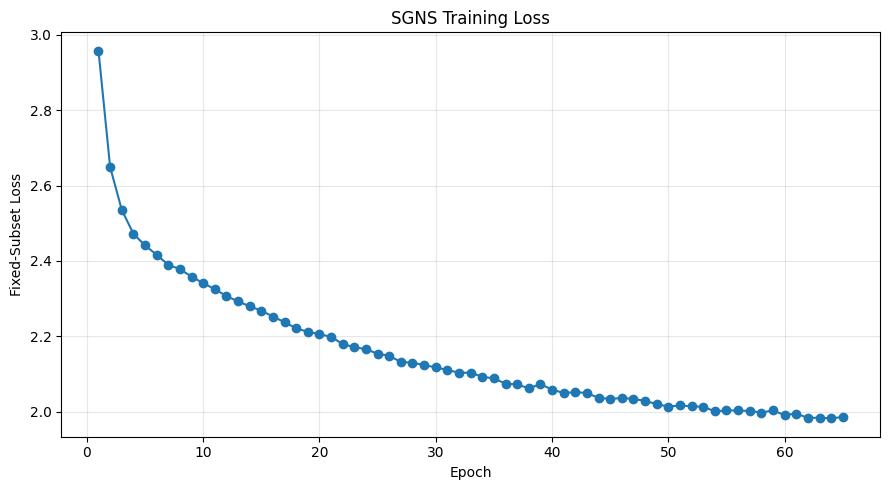


--- Save the learned embeddings ---
 Final SGNS Embedding Matrix: (4397, 50)
 Number of SGNS Embeddings: 4397


In [ ]:
# ==============================================================
# Part 1.1 - SGNS from scratch
# ==============================================================
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

min_freq = 5
window_size = 2
embedding_dim = 50
learning_rate = 0.01
k_negatives = 5
epochs = 65
batch_size = 1024

with open("datasets/brown_corpus_10k.txt", encoding="utf-8") as f:
    raw_sentences = [
        line.strip().lower()
        for line in f
        if line.strip()
    ]

# Tokenize each sentence independently.
tokenized_sentences = [
    re.findall(r"[a-z]+", sentence)
    for sentence in raw_sentences
]

# Flatten tokens only for vocabulary construction.
tokens = [
    word
    for sentence in tokenized_sentences
    for word in sentence
]

word_counts = Counter(tokens)


# Build vocabulary
print("---", "\033[1mBuild the vocabulary\033[0m", "---")
vocab_items = [
    (word, count)
    for word, count in word_counts.items()
    if count >= min_freq
]

vocab_items.sort(key=lambda x: (-x[1], x[0]))

word2idx = {
    word: idx
    for idx, (word, count) in enumerate(vocab_items)
}

idx2word = {
    idx: word
    for word, idx in word2idx.items()
}

vocab_counts = torch.tensor(
    [count for word, count in vocab_items],
    dtype=torch.float32,
    device=device
)

retained_tokens = [
    word for word in tokens
    if word in word2idx
]

vocab_size = len(word2idx)

print("Raw Tokens:", len(tokens))
print("Retained Tokens:", len(retained_tokens))
print("Vocabulary Size:", vocab_size)
print("Number of Sentences:", len(tokenized_sentences))

# Generate positive target-context pairs
# Preserve sentence boundaries and original token positions.
print("\n---","\033[1mGenerate positive target-context pairs\033[0m","---")

positive_pairs = []

for sentence in tokenized_sentences:

    for i, center_word in enumerate(sentence):

        # Skip center words outside the vocabulary.
        if center_word not in word2idx:
            continue

        center_idx = word2idx[center_word]

        start = max(0, i - window_size)
        end = min(len(sentence), i + window_size + 1)

        for j in range(start, end):

            if j == i:
                continue

            context_word = sentence[j]

            # Skip context words outside the vocabulary.
            if context_word not in word2idx:
                continue

            context_idx = word2idx[context_word]

            positive_pairs.append(
                (center_idx, context_idx)
            )

positive_pairs = torch.tensor(
    positive_pairs,
    dtype=torch.long,
    device=device
)

print("Positive Pairs Shape:", positive_pairs.shape)

print("First 5 Positive Pairs:")

for center_idx, context_idx in positive_pairs[:5].cpu().tolist():
    print(" ", idx2word[center_idx], "->", idx2word[context_idx])

# TODO: Implement Negative Sampling and initialize the embeddings.
# Build the negative sampling distribution.

print("\n---","\033[1mBuild the negative sampling distribution.\033[0m","---")
neg_weights = vocab_counts.pow(0.75)
neg_probs = neg_weights / neg_weights.sum()

# Verify that probabilities form a valid distribution.
assert torch.isclose(
    neg_probs.sum(),
    torch.tensor(1.0, device=device)
)

print(" Negative Sampling Distribution Shape:", neg_probs.shape)
print(" Probability Sum:", neg_probs.sum().item())

# Sample k negative context words for each target word.
def sample_negatives(batch_size):
    negative_samples = torch.multinomial(
        neg_probs,
        num_samples=batch_size * k_negatives,
        replacement=True
    )
    return negative_samples.view(batch_size, k_negatives)

# Initialize target and context embedding matrices.
print("\n---","\033[1mInitialize target and context embedding matrices.\033[0m","---")
init_range = 0.5 / embedding_dim

W = torch.empty(
    vocab_size,
    embedding_dim,
    device=device
).uniform_(-init_range, init_range)

C = torch.empty(
    vocab_size,
    embedding_dim,
    device=device
).uniform_(-init_range, init_range)

print("W Shape:", W.shape)
print("C Shape:", C.shape)

# TODO: Implement SGNS Loss and Gradient calculations.
# Implement SGNS loss and analytical gradients.
print("\n---","\033[1mImplement SGNS Loss and Gradient calculations.\033[0m","---")
def sgns_loss_and_grads(W, C, target_idx, positive_idx, negative_idx):
    batch_size = target_idx.shape[0]
    v_w = W[target_idx]
    u_pos = C[positive_idx]
    u_neg = C[negative_idx]

    positive_scores = torch.sum(v_w * u_pos, dim=1)
    negative_scores = torch.sum(v_w.unsqueeze(1) * u_neg, dim=2)

    positive_loss = -torch.nn.functional.logsigmoid(positive_scores)
    negative_loss = -torch.nn.functional.logsigmoid(-negative_scores).sum(dim=1)

    loss = (positive_loss + negative_loss).mean()

    # Analytical derivatives with respect to the scores.
    grad_positive_score = torch.sigmoid(positive_scores) - 1.0
    grad_negative_score = torch.sigmoid(negative_scores)

    # Gradient with respect to target embeddings.
    grad_w = (
        grad_positive_score.unsqueeze(1) * u_pos
        + torch.sum(
            grad_negative_score.unsqueeze(2) * u_neg,
            dim=1
        )
    ) / batch_size

    # Gradient with respect to positive context embeddings.
    grad_c_pos = (
        grad_positive_score.unsqueeze(1) * v_w
    ) / batch_size

    # Gradient with respect to negative context embeddings.
    grad_c_neg = (
        grad_negative_score.unsqueeze(2)
        * v_w.unsqueeze(1)
    ) / batch_size

    return loss, grad_w, grad_c_pos, grad_c_neg

# TODO: Check the gradients, train the model, and plot the loss.
# Gradient Check
print("\n---","\033[1mCheck the gradients\033[0m","---")

# Gradient checking using finite differences.
def gradient_check():
    torch.manual_seed(SEED)
    # Small vocabulary and embedding dimension for testing.
    test_vocab_size = 8
    test_dim = 4

    # Use double precision for numerical accuracy.
    test_W = torch.randn(test_vocab_size, test_dim, dtype=torch.float64) * 0.1
    test_C = torch.randn(test_vocab_size, test_dim, dtype=torch.float64) * 0.1

    # A small batch with fixed positive and negative samples.
    test_targets = torch.tensor([0, 1, 2, 1])
    test_positive = torch.tensor([1, 2, 3, 4])
    test_negative = torch.tensor([
        [2, 3, 4, 5, 6],
        [0, 3, 4, 5, 7],
        [0, 1, 4, 6, 7],
        [0, 2, 5, 6, 7]
    ])
    epsilon = 1e-5
    # Compute analytical gradients.
    loss, grad_W, grad_C_pos, grad_C_neg = (
        sgns_loss_and_grads(
            test_W,
            test_C,
            test_targets,
            test_positive,
            test_negative
        )
    )

    # Accumulate analytical gradients into full matrices.
    analytical_W = torch.zeros_like(test_W)
    analytical_C = torch.zeros_like(test_C)

    analytical_W.index_add_(0, test_targets, grad_W)
    analytical_C.index_add_(0, test_positive, grad_C_pos)
    analytical_C.index_add_(0, test_negative.reshape(-1), grad_C_neg.reshape(-1, test_dim))

    # Compute numerical gradients for selected parameters.
    numerical_W = torch.zeros_like(test_W)
    numerical_C = torch.zeros_like(test_C)

    def calculate_loss():
        return sgns_loss_and_grads(
            test_W,
            test_C,
            test_targets,
            test_positive,
            test_negative
        )[0]

    with torch.no_grad():
        for i in range(test_vocab_size):
            for j in range(test_dim):

                original = test_W[i, j].item()

                test_W[i, j] = original + epsilon
                loss_plus = calculate_loss().item()

                test_W[i, j] = original - epsilon
                loss_minus = calculate_loss().item()

                numerical_W[i, j] = (
                    loss_plus - loss_minus
                ) / (2 * epsilon)

                test_W[i, j] = original

        for i in range(test_vocab_size):
            for j in range(test_dim):

                original = test_C[i, j].item()

                test_C[i, j] = original + epsilon
                loss_plus = calculate_loss().item()

                test_C[i, j] = original - epsilon
                loss_minus = calculate_loss().item()

                numerical_C[i, j] = (
                    loss_plus - loss_minus
                ) / (2 * epsilon)

                test_C[i, j] = original

    # Calculate relative errors.
    error_W = (
        torch.norm(analytical_W - numerical_W)
        /
        torch.clamp(
            torch.norm(analytical_W) + torch.norm(numerical_W),
            min=1e-12
        )
    )

    error_C = (
        torch.norm(analytical_C - numerical_C)
        /
        torch.clamp(
            torch.norm(analytical_C) + torch.norm(numerical_C),
            min=1e-12
        )
    )

    print("Initial Test Loss:", loss.item())
    print("Relative Error W:", error_W.item())
    print("Relative Error C:", error_C.item())

    assert error_W.item() < 1e-6
    assert error_C.item() < 1e-6
    print("Gradient Check Passed!")
gradient_check()

# Create a fixed monitoring subset.
monitor_size = min(2000, len(positive_pairs))
monitor_indices = torch.randperm(len(positive_pairs), device=device)[:monitor_size]
monitor_pairs = positive_pairs[monitor_indices]
monitor_negatives = sample_negatives(monitor_size)

# Evaluate loss on the same fixed subset.
def evaluate_fixed_loss():
    targets = monitor_pairs[:, 0]
    positives = monitor_pairs[:, 1]

    loss, _, _, _ = sgns_loss_and_grads(W, C, targets, positives, monitor_negatives)
    return loss.item()

# Train SGNS using mini-batch SGD.
print("\n---","\033[1mTrain SGNS using mini-batch SGD.\033[0m","---")
loss_history = []
W_initial = W.clone()
C_initial = C.clone()
for epoch in range(epochs):
    # Shuffle positive pairs at the beginning of each epoch.
    permutation = torch.randperm(len(positive_pairs), device=device)
    shuffled_pairs = positive_pairs[permutation]

    # Process the training pairs in mini-batches.
    for start in range(0, len(shuffled_pairs), batch_size):
        batch = shuffled_pairs[start:start + batch_size]
        target_idx = batch[:, 0]
        positive_idx = batch[:, 1]

        current_batch_size = len(batch)

        # Draw negative samples for this batch.
        negative_idx = sample_negatives(current_batch_size)
        # Compute loss and analytical gradients.
        loss, grad_w, grad_c_pos, grad_c_neg = (
            sgns_loss_and_grads(
                W,
                C,
                target_idx,
                positive_idx,
                negative_idx
            )
        )

        # Update embedding matrices.
        # Accumulate per-sample gradients for SGNS.

        with torch.no_grad():

            W.index_add_(
                0,
                target_idx,
                -learning_rate * current_batch_size * grad_w
            )

            C.index_add_(
                0,
                positive_idx,
                -learning_rate * current_batch_size * grad_c_pos
            )

            C.index_add_(
                0,
                negative_idx.reshape(-1),
                -learning_rate * current_batch_size
                * grad_c_neg.reshape(-1, embedding_dim)
            )
    # Evaluate on the fixed monitoring subset.
    epoch_loss = evaluate_fixed_loss()
    loss_history.append(epoch_loss)
    print(
        f"  Epoch {epoch + 1:02d}/{epochs} "
        f"| Fixed-Subset Loss: {epoch_loss:.4f}"
    )

# Plot the fixed-subset loss across epochs.
plt.figure(figsize=(9, 5))
plt.plot(
    range(1, epochs + 1),
    loss_history,
    marker="o"
)

plt.xlabel("Epoch")
plt.ylabel("Fixed-Subset Loss")
plt.title("SGNS Training Loss")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# TODO: Save the learned embeddings for the following questions.
# Combine target and context embeddings.
print("\n---","\033[1mSave the learned embeddings\033[0m","---")
sgns_vectors = (W + C).detach().cpu().numpy()
# Create a word-to-vector dictionary.
sgns_embeddings = {
    word: sgns_vectors[idx]
    for word, idx in word2idx.items()
}

print(" Final SGNS Embedding Matrix:", sgns_vectors.shape)
print(" Number of SGNS Embeddings:", len(sgns_embeddings))


In [ ]:
# Save embeddings on drive
save_dir = '/content/drive/MyDrive/NLP_CA2'
os.makedirs(save_dir, exist_ok=True)

E = W + C

checkpoint = {
    'W': W.detach().cpu(),
    'C': C.detach().cpu(),
    'E': E.detach().cpu(),
    'vocab': vocab_items,
    'word_to_idx': word2idx,
    'embedding_dim': embedding_dim,
    'min_freq': min_freq,
    'window_size': window_size,
    'k_negatives': k_negatives
}
save_path = os.path.join(save_dir, 'sgns_embeddings.pt')
torch.save(checkpoint, save_path)

In [ ]:
# Compare positive and negative scores after training.
with torch.no_grad():
    sample_pairs = positive_pairs[:5000]

    targets = sample_pairs[:, 0]
    contexts = sample_pairs[:, 1]

    positive_scores = (
        W[targets] * C[contexts]
    ).sum(dim=1)

    test_negatives = sample_negatives(len(sample_pairs))

    negative_scores = (
        W[targets].unsqueeze(1)
        * C[test_negatives]
    ).sum(dim=2)

    print("Average Positive Score:", positive_scores.mean().item())
    print("Average Negative Score:", negative_scores.mean().item())

Average Positive Score: -0.5604792237281799
Average Negative Score: -2.8503737449645996


In [ ]:
print("W Change:", torch.norm(W - W_initial).item())
print("C Change:", torch.norm(C - C_initial).item())

W Change: 244.11849975585938
C Change: 260.3392028808594


In [ ]:
with torch.no_grad():
    print("W norm:", torch.norm(W).item())
    print("C norm:", torch.norm(C).item())

    print("W mean abs:", W.abs().mean().item())
    print("C mean abs:", C.abs().mean().item())

    print("W max abs:", W.abs().max().item())
    print("C max abs:", C.abs().max().item())

W norm: 244.1664581298828
C norm: 260.3849792480469
W mean abs: 0.41485166549682617
C mean abs: 0.44336721301078796
W max abs: 2.784410238265991
C max abs: 2.449279546737671


<div dir="rtl" style="box-sizing:border-box; max-width:100%; background-color:#FFF8E7; color:#2B2317; border-right:4px solid #D9A441; border-radius:6px; padding:16px 20px; margin:6px 0; line-height:1.9; text-align:right; overflow-wrap:break-word;">

<b style="color:#8A6116;">پاسخ تشریحی ۱.۱</b>

<p><strong>سؤال ۱.</strong> با افزایش تعداد Negative Samples یعنی k، چه تغییری در Gradient مربوط به Target Word Vector یعنی w ایجاد می‌شود؟</p>

<p><strong>سؤال ۲.</strong> چرا پس از Training، دو Matrix به نام W و C را با هم جمع می‌کنند؟</p>

<p><strong>سؤال ۳.</strong> منظور از Fixed-Subset Loss در Training مدل SGNS چیست و چرا از آن استفاده می‌کنیم؟</p>

---

<strong>پاسخ پرسش 1</strong>
<p>
 با افزایش تعداد Negative Samples، تعداد ترم های مربوط به نمونه‌های منفی در تابع Loss افزایش می‌یابد. در نتیجه، گرادیان Target Word Vector شامل مجموع سهم گرادیان‌های تعداد بیشتری از Negative Contextها می‌شود. پس اطلاعات بیشتری برای دور کردن Target از Contextهای منفی در اختیار مدل قرار می‌گیرد.

 البته باید بگویم که افزایش k الزاما باعث افزایش اندازه گرادیان نیست، چون ممکن اس جهت و اندازه بردارهای مختلف، روی یکدیگر اثر های متفاوتی بگذارند.
</p>

<strong>پاسخ پرسش 2</strong>
<p>
همانطور که میدانیم، در این روش، ماتریس W بردارهای واژگان تارگت و ماتریس C بردارهای واژگان کانتکست را در خود نگه می دارد.

با توجه به روابط محاسبه لاس و تغییر این بردارها،  هر ماتریس از طریق روابط متفاوتی با سایر واژه‌ها آموزش می‌بیند. پس ترکیب این دو ماتریس با استفاده از رابطه \(E=W+C\)، یک نمایش نهایی ایجاد می‌کند که اطلاعات یادگرفته شده در هر دو نقش را در
خود دارد.
پس با این کار، عملا دو دسته یادگیری مختلف را با هم ادغام می کنیم و در نهایت بردار های معنادارتری بدست خواهیم آورد.
</p>

<strong>پاسخ پرسش 3</strong>
<p>
Fixed-Subset Loss به معنی محاسبه Loss روی یک مجموعه ثابت از Positive Pairs و Negative Samples در طول Epochهای مختلف است. از آنجا که Negative Sampling تصادفی است، محاسبه Loss روی نمونه‌های متفاوت می‌تواند باعث ایجاد نوسان در مقادیر گزارش‌شده شود، یعنی ما متوجه نمی شویم که این نوسانات احتمالی واقعا یادنگرفتن مدل را نشان می دهند یا بدلیل انتخاب نمونه های تصادفی با این نوسانات روبه رو می شویم. پس با ثابت نگه‌داشتن مجموعه ارزیابی، می‌توان تغییر Loss را بهتر به پیشرفت مدل در یادگیری Embeddings نسبت داد و روند همگرایی آن را با اطمینان بیشتری بررسی کرد.
</p>


</div>

<div dir="rtl" align="right">

### ۱.۲ ارزیابی Analogy و مقایسه با GloVe

**صورت مسئله**

کیفیت Word Embeddings آموزش‌دیده با SGNS را با استفاده از Nearest Neighbors و Analogy Tests بررسی کنید و نتایج را با Embeddings از پیش آموزش‌دیده‌ی GloVe مقایسه کنید.

**آنچه باید انجام دهید**

- Embeddings از پیش آموزش‌دیده‌ی GloVe با Dimension برابر ۵۰ را بارگذاری کنید.
- Nearest Neighbors مربوط به واژه‌های منتخب را با استفاده از Cosine Similarity پیدا کنید.
- Analogy Queries را با Vector Arithmetic ارزیابی کنید.
- نتایج SGNS و GloVe را برای واژه‌ها و Analogyهای یکسان مقایسه کنید.

**خروجی مورد انتظار**

- فهرست Nearest Neighbors و Cosine Similarity آن‌ها برای هر دو مدل.
- نتایج Analogy Tests و گزارش واژه‌های خارج از Vocabulary یا OOV.
- تحلیل تفاوت نتایج دو مدل و محدودیت‌های این ارزیابی.

**نکات و محدودیت‌ها**

- برای مقایسه‌ی منصفانه، از Analogy Queries یکسان در هر دو مدل استفاده کنید.
- واژه‌های ورودی را از فهرست پاسخ‌های Nearest Neighbors و Analogy حذف کنید.
- مشخص کنید که آیا واژه‌های ورودی در Vocabulary هر مدل موجود هستند یا خیر.

</div>

In [ ]:
# ==============================================================
# Part 1.2 - Analogy evaluation
# ==============================================================

# I changed the path because I had glove.6B folder and .txt in it
glove_path = "/content/datasets/glove.6B/glove.6B.50d.txt"

# TODO: Load the pretrained GloVe embeddings.
print("\n---","\033[1mLoad the pretrained GloVe embeddings\033[0m","---")
glove_embeddings = {}
with open(glove_path, encoding="utf-8") as f:
    for line in f:
        parts = line.rstrip().split()
        # Skip malformed lines.
        if len(parts) != 51:
            continue
        word = parts[0]
        vector = np.asarray(parts[1:], dtype=np.float32)
        glove_embeddings[word] = vector

glove_words = list(glove_embeddings.keys())
glove_matrix = np.stack([glove_embeddings[word] for word in glove_words])

print("GloVe vocabulary size:", len(glove_words))
print("GloVe embedding dimension:", glove_matrix.shape[1])

# Prepare the SGNS embeddings
print("\n---","\033[1mPrepare the SGNS embeddings\033[0m","---")
sgns_matrix = E.detach().cpu().numpy().astype(np.float32)
sgns_words = [None] * len(word2idx)

for word, idx in word2idx.items():
    sgns_words[idx] = word

print("SGNS vocabulary size:", len(sgns_words))
print("SGNS embedding dimension:", sgns_matrix.shape[1])

# Normalize embedding matrices for cosine similarity
def normalize_embeddings(matrix):
    # Normalize each row to unit length.
    norms = np.linalg.norm(matrix, axis=1, keepdims=True)
    norms = np.maximum(norms, 1e-12)
    return matrix / norms

sgns_normalized = normalize_embeddings(sgns_matrix)
glove_normalized = normalize_embeddings(glove_matrix)

# Create word-to-index mappings.
sgns_word_to_idx = {word: idx for idx, word in enumerate(sgns_words)}
glove_word_to_idx = {word: idx for idx, word in enumerate(glove_words)}

# TODO: Find Nearest Neighbors using Cosine Similarity.
print("\n---","\033[1mFind Nearest Neighbors using Cosine Similarity\033[0m","---")

def find_nearest_neighbors(word, word_to_idx, words, normalized_matrix, top_k=5):
    # Return None if the query word is out of vocabulary.
    if word not in word_to_idx:
        return None

    # Get the normalized query vector.
    query_idx = word_to_idx[word]
    query_vector = normalized_matrix[query_idx]
    similarities = normalized_matrix @ query_vector
    similarities[query_idx] = -np.inf
    top_indices = np.argsort(similarities)[::-1][:top_k]

    return [(words[idx], float(similarities[idx])) for idx in top_indices]
# Use the same query words for both models.
selected_words = ["man", "he", "woman", "boy", "girl"]
print("\n---","\033[1mNEAREST NEIGHBORS\033[0m","---")
for word in selected_words:
    print(f"\nQuery word: {word}")
    for model_name, word_to_idx, words, matrix in [
        ("SGNS", sgns_word_to_idx, sgns_words, sgns_normalized),
        ("GloVe", glove_word_to_idx, glove_words, glove_normalized)
    ]:
        neighbors = find_nearest_neighbors(
            word, word_to_idx, words, matrix, top_k=5
        )

        if neighbors is None:
            print(f"{model_name}: OOV")
        else:
            print(f"{model_name}:")
            for neighbor, score in neighbors:
                print(f"  {neighbor:15s} cosine similarity = {score:.4f}")

# TODO: Evaluate the following analogies for SGNS and GloVe.
# WRITE YOUR CODE HERE

analogy_queries = [
    ("man", "he", "woman"),
    ("boy", "man", "girl"),
]


def solve_analogy(
    a, b, c,
    word_to_idx,
    words,
    original_matrix,
    normalized_matrix,
    top_k=5
):
    # Check whether all input words exist in the vocabulary.
    input_words = [a, b, c]
    missing_words = [word for word in input_words if word not in word_to_idx]

    if missing_words:
        return None, missing_words

    # Apply vector arithmetic using the original embeddings.
    a_vector = original_matrix[word_to_idx[a]]
    b_vector = original_matrix[word_to_idx[b]]
    c_vector = original_matrix[word_to_idx[c]]

    result_vector = b_vector - a_vector + c_vector

    # Normalize the resulting vector.
    result_norm = np.linalg.norm(result_vector)
    if result_norm < 1e-12:
        return [], []

    result_vector = result_vector / result_norm

    # Compute cosine similarity with all normalized vocabulary vectors.
    similarities = normalized_matrix @ result_vector

    # Exclude all input words from the candidate answers.
    for word in input_words:
        similarities[word_to_idx[word]] = -np.inf

    # Retrieve the top-k candidate answers.
    top_indices = np.argsort(similarities)[::-1][:top_k]

    results = [
        (words[idx], float(similarities[idx]))
        for idx in top_indices
    ]

    return results, []

print("\n---","\033[1mANALOGY TESTS\033[0m","---")
for a, b, c in analogy_queries:
    print(f"\nAnalogy: {a} : {b} :: {c} : ?")

    for model_name, word_to_idx, words, matrix in [
        ("SGNS", sgns_word_to_idx, sgns_words, sgns_normalized),
        ("GloVe", glove_word_to_idx, glove_words, glove_normalized)
    ]:
        original_matrix = (
        sgns_matrix if model_name == "SGNS" else glove_matrix
        )

        results, missing_words = solve_analogy(
            a, b, c,
            word_to_idx,
            words,
            original_matrix,
            matrix,
            top_k=5
        )

        if missing_words:
            print(f"{model_name}: OOV words = {missing_words}")
        else:
            print(f"{model_name}:")
            for candidate, score in results:
                print(f"  {candidate:15s} cosine similarity = {score:.4f}")




# TODO: Compare the results and report any OOV words.
print("\n---","\033[1mVOCABULARY COVERAGE\033[0m","---")
all_test_words = sorted(set(
    selected_words +
    [word for query in analogy_queries for word in query]
))

for model_name, word_to_idx in [
    ("SGNS", sgns_word_to_idx),
    ("GloVe", glove_word_to_idx)
]:
    oov_words = [word for word in all_test_words if word not in word_to_idx]

    print(f"\n{model_name}:")
    print("Total tested words:", len(all_test_words))
    print("OOV words:", oov_words)
    print("In-vocabulary words:", len(all_test_words) - len(oov_words))



--- Load the pretrained GloVe embeddings ---
GloVe vocabulary size: 400000
GloVe embedding dimension: 50

--- Prepare the SGNS embeddings ---
SGNS vocabulary size: 4397
SGNS embedding dimension: 50

--- Find Nearest Neighbors using Cosine Similarity ---

--- NEAREST NEIGHBORS ---

Query word: man
SGNS:
  moss            cosine similarity = 0.6435
  actor           cosine similarity = 0.6339
  young           cosine similarity = 0.6125
  woman           cosine similarity = 0.6118
  himself         cosine similarity = 0.5958
GloVe:
  woman           cosine similarity = 0.8860
  boy             cosine similarity = 0.8564
  another         cosine similarity = 0.8453
  old             cosine similarity = 0.8372
  one             cosine similarity = 0.8276

Query word: he
SGNS:
  she             cosine similarity = 0.6430
  said            cosine similarity = 0.6154
  write           cosine similarity = 0.6131
  slate           cosine similarity = 0.5902
  liston          cosine similarity 

<div dir="rtl" style="box-sizing:border-box; max-width:100%; background-color:#FFF8E7; color:#2B2317; border-right:4px solid #D9A441; border-radius:6px; padding:16px 20px; margin:6px 0; line-height:1.9; text-align:right; overflow-wrap:break-word;">

<b style="color:#8A6116;">پاسخ تشریحی ۱.۲</b>

<p><strong>سؤال.</strong> چرا مدل SGNS این تمرین ممکن است در Analogy Tests از GloVe ضعیف‌تر باشد؟ آیا Nearest Neighbors و چند Analogy Test برای سنجش کیفیت کلی Embeddings کافی‌اند؟ روش Parallelogram چه محدودیت‌هایی دارد؟</p>

---

<strong>پاسخ پرسش 1.2 و تحلیل خروجی</strong>

<p>
خروجی های سلول بالا نشان می‌دهند که مدل GloVe در هر دو بخش Nearest Neighbors و Analogy Tests عملکرد بهتری نسبت به مدل SGNS که ما train کردیم دارد. در آزمایش Nearest Neighbors،  مدل GloVe روابط معنایی منسجم‌تری میان واژه‌ها ایجاد می‌کند؛ به‌عنوان مثال، برای واژه‌های <em>man</em>، <em>woman</em>، <em>boy</em> و <em>girl</em> همسایه‌هایی پیدا می‌شود که از نظر معنایی و مفهومی به یکدیگر مرتبط‌اند. در مقابل، SGNS علاوه بر برخی همسایه‌های مناسب، تعدادی واژه با ارتباط معنایی ضعیف یا نامشخص هم خروجی داده است که نشان‌ می دهد کیفیت نمایش‌های برداری آن به قدرت مدل GloVe نیست.
</p>

<p>
در بخش  Analogy Tests هم نتایج به نفع GloVe هستند. مثلا برای رابطه:
</p>

<p style="text-align:center;">
man : he :: woman : she
</p>

<p>
مدل GloVe واژه she را در رتبه اول قرار داده، در حالی که SGNS آن را در رتبه چهارم بازیابی می‌کند.

همچنین در رابطه:
</p>

<p style="text-align:center;">
boy : man :: girl : woman
</p>

<p>
مدل GloVe واژه woman را در رتبه نخست قرار می‌دهد، اما SGNS حتی آن را در میان پنج پاسخ اول خود نیز قرار نمی‌دهد. بنابراین GloVe هر دو تست را به‌درستی حل می‌کند، در حالی که SGNS تنها در تست اول تا حدی موفق است.
</p>

<p>
یکی از مهم‌ترین دلایل این اختلاف عملکرد، تفاوت در حجم داده‌های آموزشی است. مدل SGNS که ما train کردیم تنها بر روی داده های Brown آموزش داده شده و واژگان آن شامل حدود ۴۳۹۷ کلمه است، در حالی که نسخه‌ی آماده GloVe دارای واژگانی در حدود ۴۰۰ هزار کلمه است. علاوه بر این، برخی واژه‌های مورد ارزیابی مانند <em>woman</em>، <em>boy</em> و <em>girl</em> در پیکره آموزشی تعداد تکرار کمی داشته‌اند و در نتیجه اطلاعات زمینه‌ای کافی برای یادگیری بردارهای پایدار و دقیق در اختیار مدل قرار نگرفته است.
</p>

<p>
دلیل دیگری که ممکن است وجود داشته باشد، به ماهیت SGNS مربوط می‌شود. ما این مدل را به گونه ای آموزش دادیم که  جفت‌های «word-context» واقعی رااز نمونه‌های منفی تشخیص دهد و مستقیماً برای حل analogy test بهینه‌سازی نکردیم. در نتیجه، هرچند روابط خطی میان بردارها گاهی می‌توانند قیاس‌ هایی مثل

v(he) − v(man) + v(woman) ≈ v(she)

<p>
را نمایان کنند، اما همه روابط معنایی الزاما به شکل یک اختلاف برداری ثابت در فضای تعبیه نمایش داده نمی‌شوند.
</p>

<p>
روش Parallelogram نیز محدودیت‌های مهمی دارد. این روش فرض می‌کند که یک رابطه معنایی معین همواره با یک جابه‌جایی برداری ثابت قابل نمایش است. با این حال، معنای واژه‌ها اغلب وابسته به بافت هستند و ممکن است چندین معنا داشته باشند. بنابراین روابط معنایی پیچیده زبان طبیعی همیشه با این فرض ساده قابل مدل‌سازی نیستند و نتایج قیاس‌های برداری تنها یک تقریب از روابط زبانی واقعی محسوب می‌شوند.
</p>

<p>
همچنین واضح است که ارزیابی کیفیت Embeddings تنها با استفاده از چند نمونه Nearest Neighbor و دو یا چند Analogy Test کافی نیست. چنین ارزیابی‌هایی تنها بخشی از ویژگی‌های نمایش برداری را بررسی می‌کنند و ممکن است نتایج آن‌ها به انتخاب واژه‌ها و سؤالات وابسته باشد. برای اینکه دقیق تر بتوانیم قضاوت کنیم لازم است مجموعه بزرگ‌تری از قیاس‌ها، واژه‌ها و همچنین تسک های دیگری مانند طبقه‌بندی متن، تحلیل احساسات یا بازیابی اطلاعات مورد استفاده قرار گیرد.
</p>

<p>
در مجموع، نتایج این آزمایش نشان می‌دهد که GloVe در این مجموعه ارزیابی محدود عملکرد بهتری از SGNS دارد؛ اما به دلیل تفاوت در اندازه داده های آموزشی، اندازه واژگان و کوچک بودن مجموعه آزمون، نمی‌توان با اطمینان نتیجه گرفت که GloVe در همه شرایط به طور مطلق از SGNS برتر است. برای دستیابی به نتیجه‌ای کلی‌تر به ارزیابی‌های گسترده‌تر و متنوع‌تر نیاز خواهد بود.
</p>

</div>

<div dir="rtl" align="right">

### ۱.۳ نمایش PCA برای Word Embeddings

**صورت مسئله**

برای بررسی بصری Word Embeddings، بردارهای واژه‌های انتخاب‌شده از SGNS و GloVe را با استفاده از Principal Component Analysis (PCA) به دو Dimension کاهش دهید و نتایج را رسم کنید.

**آنچه باید انجام دهید**

- مجموعه‌ای از واژه‌های مشترک را از Vocabulary هر دو مدل انتخاب کنید.
- Embeddings مربوط به واژه‌های منتخب را به دو Dimension کاهش دهید.
- برای هر مدل یک Plot دوبعدی رسم کنید و نام هر واژه را روی Plot نمایش دهید.

**خروجی مورد انتظار**

- یک PCA Plot برای SGNS و یک PCA Plot برای GloVe.
- گزارش مجموع Explained Variance Ratio مربوط به دو Principal Components اول برای هر مدل.
- تحلیل الگوهای قابل مشاهده و محدودیت‌های PCA Visualization.

**نکات و محدودیت‌ها**

- PCA را برای هر مدل به‌صورت جداگانه Fit کنید.

</div>

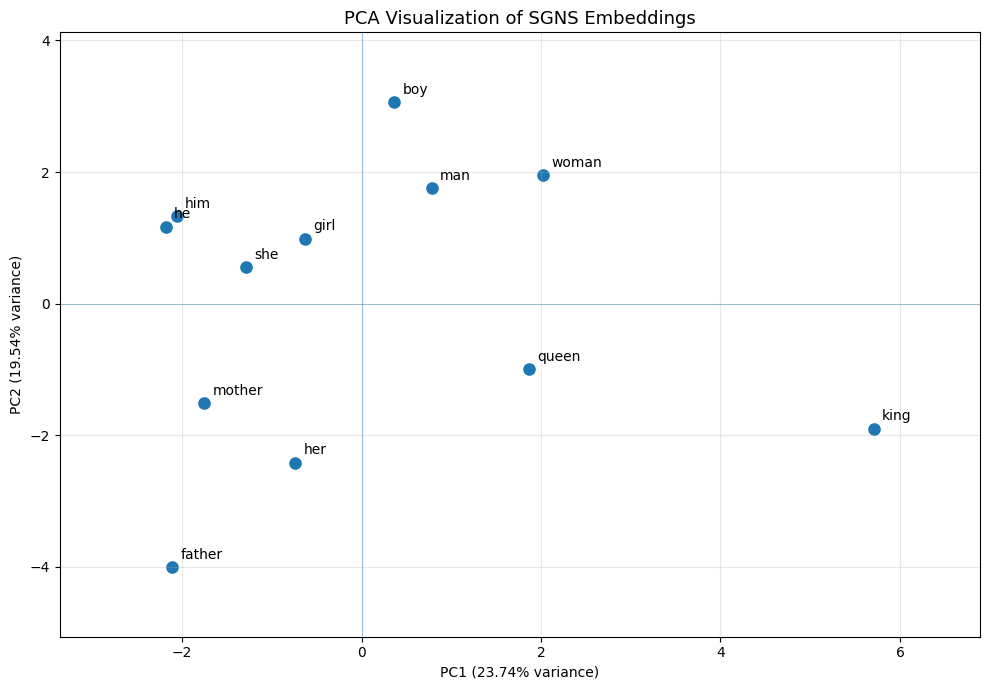

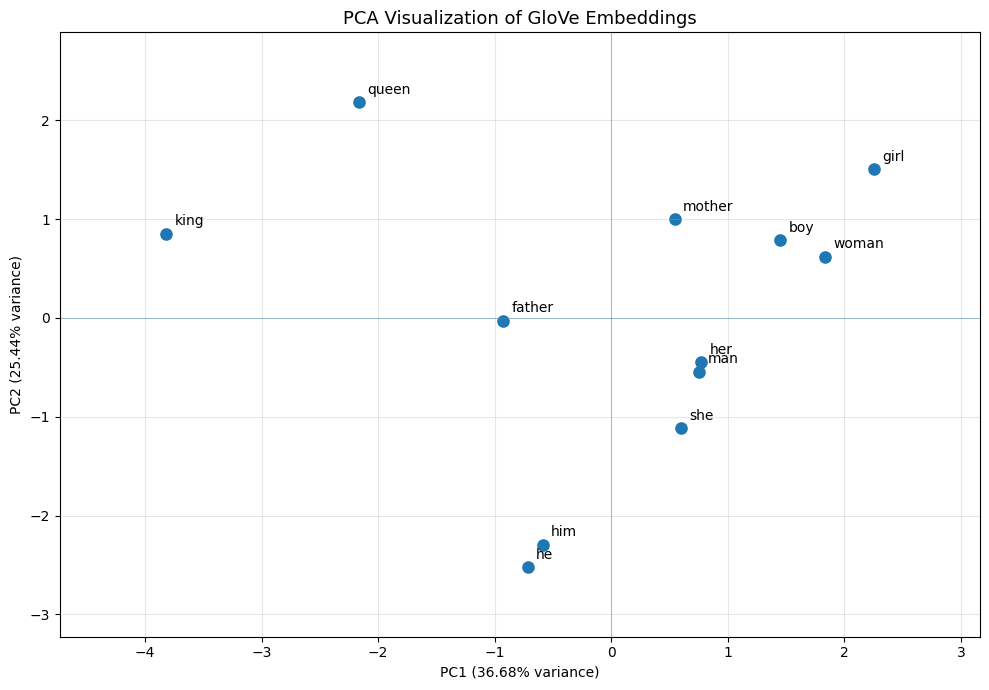


--- Explained Variance Analysis ---
  
SGNS:
  PC1 Explained Variance: 0.2374 (23.74%)
  PC2 Explained Variance: 0.1954 (19.54%)
  Total Explained Variance: 0.4328 (43.28%)
  
GloVe:
  PC1 Explained Variance: 0.3668 (36.68%)
  PC2 Explained Variance: 0.2544 (25.44%)
  Total Explained Variance: 0.6212 (62.12%)


In [ ]:
# ==============================================================
# Part 1.3 - PCA visualization
# ==============================================================

words_to_plot = [
    "man", "woman", "boy", "girl",
    "he", "she", "him", "her",
    "father", "mother", "king", "queen",
]

def plot_pca_result(coordinates, words, pca_model, model_name):
    fig, ax = plt.subplots(figsize=(10, 7))
    ax.scatter(
        coordinates[:, 0],
        coordinates[:, 1],
        s=65
    )
    # Annotate each point with its corresponding word.
    for i, word in enumerate(words):
        x, y = coordinates[i]
        ax.annotate(word, (x, y), xytext=(6, 6), textcoords="offset points", fontsize=10)

    # Calculate the explained variance of the first two components.
    pc1_variance = pca_model.explained_variance_ratio_[0] * 100
    pc2_variance = pca_model.explained_variance_ratio_[1] * 100

    # Add titles and axis labels.
    ax.set_title(f"PCA Visualization of {model_name} Embeddings", fontsize=13)

    ax.set_xlabel(f"PC1 ({pc1_variance:.2f}% variance)")
    ax.set_ylabel(f"PC2 ({pc2_variance:.2f}% variance)")

    # Improve plot readability.
    ax.axhline(0, linewidth=0.7, alpha=0.4)
    ax.axvline(0, linewidth=0.7, alpha=0.4)

    ax.grid(alpha=0.3)
    ax.margins(0.15)

    plt.tight_layout()
    plt.show()

# TODO: Apply PCA to the selected SGNS embeddings and plot the results.
# Extract SGNS and GloVe vectors in the same word order.
sgns_selected = np.stack([sgns_matrix[sgns_word_to_idx[word]] for word in words_to_plot])

# Fit PCA on SGNS embeddings.
pca_sgns = PCA(n_components=2)
sgns_2d = pca_sgns.fit_transform(sgns_selected)

# Generate the SGNS PCA plot.
plot_pca_result(sgns_2d, words_to_plot, pca_sgns, "SGNS")


# TODO: Apply PCA separately to the selected GloVe embeddings and plot them.
# Extract GloVe and GloVe vectors in the same word order.
glove_selected = np.stack([glove_matrix[glove_word_to_idx[word]] for word in words_to_plot])

# Fit PCA on GloVe embeddings.
pca_glove = PCA(n_components=2)
glove_2d = pca_glove.fit_transform(glove_selected)

# Generate the GloVe PCA plot.
plot_pca_result(glove_2d, words_to_plot, pca_glove, "GloVe")


# TODO: Report the explained variance for the first two components.
print("\n---","\033[1mExplained Variance Analysis\033[0m","---")
for model_name, pca_model in [("SGNS", pca_sgns),("GloVe", pca_glove)]:
    pc1 = pca_model.explained_variance_ratio_[0]
    pc2 = pca_model.explained_variance_ratio_[1]

    total_variance = pc1 + pc2

    print(f"  \n{model_name}:")
    print(f"  PC1 Explained Variance: {pc1:.4f} ({pc1 * 100:.2f}%)")
    print(f"  PC2 Explained Variance: {pc2:.4f} ({pc2 * 100:.2f}%)")
    print(
        f"  Total Explained Variance: "
        f"{total_variance:.4f} ({total_variance * 100:.2f}%)"
    )

<div dir="rtl" style="box-sizing:border-box; max-width:100%; background-color:#FFF8E7; color:#2B2317; border-right:4px solid #D9A441; border-radius:6px; padding:16px 20px; margin:6px 0; line-height:1.9; text-align:right; overflow-wrap:break-word;">

<b style="color:#8A6116;">پاسخ تشریحی ۱.۳</b>

<p><strong>سؤال.</strong> Plotهای PCA چه اطلاعاتی درباره‌ی توزیع واژه‌ها و روابط میان آن‌ها نشان می‌دهند؟ مجموع Explained Variance Ratio مربوط به دو Principal Components اول چه مفهومی دارد؟ چرا نباید مختصات واژه‌ها را بین دو Plot مستقیما مقایسه کرد؟</p>

---

<strong>پاسخ پرسش 1.3 و تحلیل خروجی</strong>

<p>
نمودارهای PCA نمایش دوبعدی بردارهای واژه‌ها هستند. در این آزمایش، هر واژه در ابتدا دارای یک بردار ۵۰بعدی است که با استفاده از PCA به دو مؤلفه اصلی (PC1 و PC2) کاهش یافته تا بتوان آن را در یک نمودار دوبعدی نمایش داد.

هر نقطه در نمودار نشان‌دهنده یک واژه است. واژه‌هایی که در نمودار به یکدیگر نزدیک‌تر هستند، معمولاً بردارهای مشابه‌تری دارند و می‌توانند از نظر معنایی یا کاربردی به هم مرتبط باشند. همچنین، گروه‌بندی نقاط می‌تواند نشان‌دهنده الگوهایی باشد که مدل در روابط میان واژه‌ها یاد گرفته است. البته باید توجه داشت که این نزدیکی‌ها در فضای دوبعدی تقریبی هستند و لزوماً تمام شباهت‌های موجود در فضای اصلی ۵۰بعدی را نشان نمی‌دهند.

در نمودار GloVe، برای مثال، واژه‌های he و him بسیار نزدیک به یکدیگر قرار گرفته‌اند. همچنین واژه‌های boy، girl و woman در ناحیه نسبتاً نزدیکی دیده می‌شوند. این موقعیت‌ها تا حدی با روابط معنایی و کاربردی میان این واژه‌ها سازگار هستند.

در نمودار SGNS نیز واژه‌های he و him به یکدیگر نزدیک‌اند و واژه‌های she و girl نیز در موقعیت‌های نسبتاً نزدیکی قرار دارند. همچنین واژه‌های man، boy و woman در بخش سمت راست نمودار دیده می‌شوند.

در مجموع، هر دو مدل توانسته‌اند برخی روابط میان واژه‌ها را یاد بگیرند، اما نحوه توزیع واژه‌ها و ساختار فضایی آن‌ها متفاوت است.
</p>

---

<p>
مقدار Explained Variance Ratio نشان می‌دهد هر مؤلفه اصلی چه نسبتی از واریانس کل داده‌ها را توضیح می‌دهد. به عبارت دیگر، این مقدار مشخص می‌کند چه میزان از پراکندگی و اطلاعات آماری موجود در بردارهای اصلی، توسط هر مؤلفه حفظ شده است.

دو مؤلفه اصلی اول در مدل GloVe در مجموع 62.12 درصد از واریانس داده‌ها را حفظ می‌کنند، درحالی‌که این مقدار برای SGNS برابر با 43.28 درصد است.

این نتیجه نشان می‌دهد که نمایش دوبعدی GloVe نسبت به نمایش دوبعدی SGNS، بخش بیشتری از ساختار آماری و پراکندگی بردارهای اصلی را حفظ کرده است. در نتیجه، نمودار دوبعدی GloVe تصویر کامل‌تری از ساختار داده‌های اصلی ارائه می‌دهد.
</p>

---

<p>همچنین باید اشاره کنم که مختصات واژه‌ها در دو نمودار قابل‌مقایسه مستقیم نیستند، زیرا دو مدل GloVe و SGNS فضای برداری متفاوتی ایجاد کرده‌اند و الگوریتم PCA نیز برای هر مدل به‌صورت مستقل اجرا شده است.

در نتیجه، مؤلفه‌های اصلی PC1 و PC2 در دو نمودار جهت‌ها و معانی یکسانی ندارند. همچنین، جهت و علامت محورهای PCA می‌تواند متفاوت باشد. بنابراین، قرار گرفتن یک واژه در مختصات متفاوت در دو نمودار لزوماً به معنای تفاوت مستقیم در کیفیت نمایش آن واژه نیست.
</p>

</div>

<div dir="rtl" align="right">

### ۲.۱ پیاده‌سازی Logistic Regression از پایه

**صورت مسئله**

یک Logistic Regression برای پیش‌بینی Positive یا Negative بودن Sentiment متن آموزش دهید. برای این کار از Features استخراج‌شده از متن استفاده کنید و Training را با پیاده‌سازی دستی Stochastic Gradient Descent (SGD) انجام دهید.

**آنچه باید انجام دهید**

- Positive و Negative Lexiconها و مجموعه‌داده‌ی IMDB را بارگذاری کنید.
- متن هر Review را به یک Feature Vector عددی تبدیل کنید. برای شروع، می‌توانید از Features پیشنهادی زیر استفاده کنید:
  - تعداد واژه‌های موجود در Positive Lexicon.
  - تعداد واژه‌های موجود در Negative Lexicon.
  - وجود یا عدم وجود واژه‌ی "no".
  - تعداد Pronounهای مشخص‌شده در کد.
  - وجود یا عدم وجود علامت "!".
  - لگاریتم تعداد Tokenهای متن.
- داده‌ها را به Train و Test تقسیم کنید و Featureها را با استفاده از آمار Training Set استانداردسازی کنید.
- Logistic Regression را با Manual SGD آموزش دهید.
- Training Loss، Weights و Bias را گزارش کنید.
- عملکرد مدل را با Classification Threshold برابر 0.5 ارزیابی کنید و نتایج را برای Threshold برابر 0.8 نیز بررسی کنید.

**خروجی مورد انتظار**

- نمودار Training Cross-Entropy برحسب Epoch.
- Weights و Bias آموزش‌دیده‌ی مدل.
- Confusion Matrix و معیارهای Accuracy، Precision، Recall و F1 برای Threshold برابر 0.5.
- مقایسه‌ی Precision و Recall برای Thresholdهای 0.5 و 0.8.

**نکات و محدودیت‌ها**

- آموزش Logistic Regression باید به‌صورت دستی انجام شود. از مدل آماده‌ی Logistic Regression برای Training استفاده نکنید.
- از یک Train/Test Split ثابت و Stratified استفاده کنید.
- برای جلوگیری از Test Data Leakage، Normalization Statistics را فقط از Training Set محاسبه کنید.
- در تحلیل، تاثیر Classification Threshold بر Precision و Recall را توضیح دهید.

</div>

 Training samples: 1600
 Testing samples: 400
Epoch 10/100 - Training Loss: 0.540264
Epoch 20/100 - Training Loss: 0.540260
Epoch 30/100 - Training Loss: 0.538647
Epoch 40/100 - Training Loss: 0.538358
Epoch 50/100 - Training Loss: 0.537925
Epoch 60/100 - Training Loss: 0.539988
Epoch 70/100 - Training Loss: 0.538015
Epoch 80/100 - Training Loss: 0.538210
Epoch 90/100 - Training Loss: 0.538148
Epoch 100/100 - Training Loss: 0.541928

Training completed.
Training diverged: False

Learned weights:
        Feature    Weight
 positive_count  1.596974
 negative_count -1.544052
         has_no -0.365844
  pronoun_count -0.026720
has_exclamation  0.017735
log_token_count -0.200093

Learned bias:
-0.07818545541675553


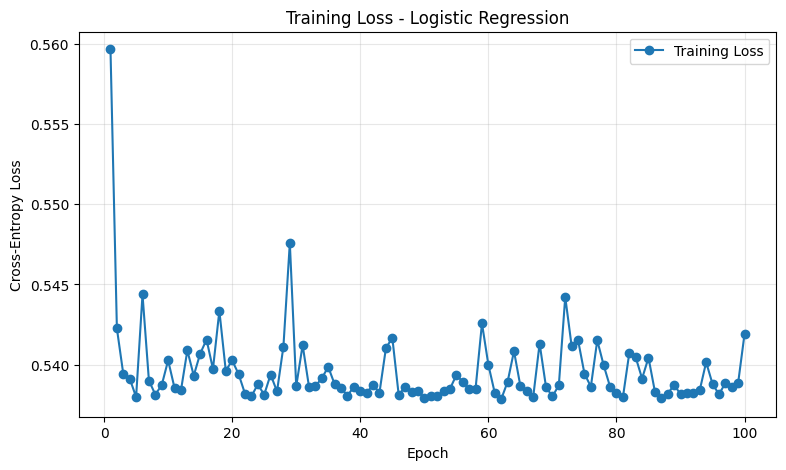

Confusion Matrix - Threshold 0.5:
[[145  55]
 [ 52 148]]


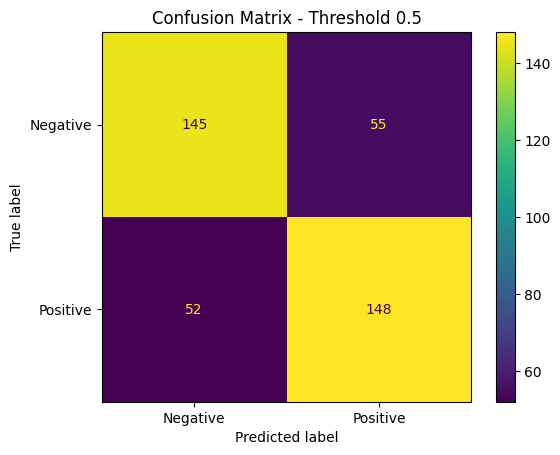

Confusion Matrix - Threshold 0.8:
[[193   7]
 [150  50]]


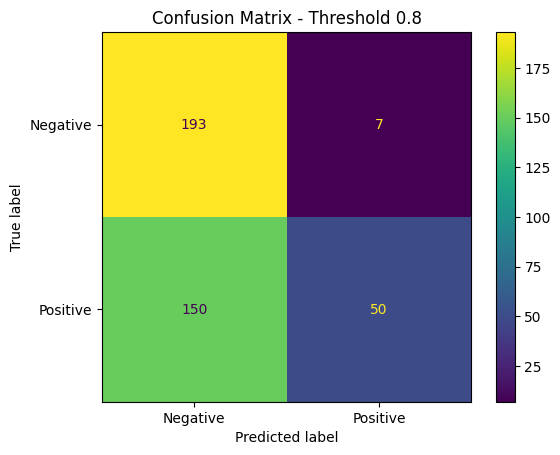


Evaluation Metrics Comparison:
 Threshold  Accuracy  Precision  Recall  F1-Score
       0.5    0.7325   0.729064    0.74  0.734491
       0.8    0.6075   0.877193    0.25  0.389105


In [ ]:
# ==============================================================
# Part 2.1 - Logistic Regression from scratch
# ==============================================================

eta = 0.01
epochs = 100

df = pd.read_csv("datasets/imdb_2k.csv")

with open("datasets/positive_words.txt", encoding="utf-8") as f:
    positive_lexicon = {line.strip().lower() for line in f if line.strip()}

with open("datasets/negative_words.txt", encoding="utf-8") as f:
    negative_lexicon = {line.strip().lower() for line in f if line.strip()}

# TODO: Extract numerical features from the text.
pronouns = {
    "i", "me", "my", "mine",
    "we", "us", "our", "ours",
    "you", "your", "yours",
    "he", "him", "his",
    "she", "her", "hers",
    "it", "its",
    "they", "them", "their", "theirs"
}

# Pronouns specified for this exercise
pronouns = {
    "i", "me", "my", "mine",
    "we", "us", "our", "ours",
    "you", "your", "yours",
    "he", "him", "his",
    "she", "her", "hers",
    "it", "its",
    "they", "them", "their", "theirs"
}

def extract_features(review):
    review = str(review).lower()
    tokens = re.findall(r"[a-z]+", review)

    positive_count = sum(1 for token in tokens if token in positive_lexicon)
    negative_count = sum(1 for token in tokens if token in negative_lexicon)
    has_no = int("no" in tokens)
    pronoun_count = sum(1 for token in tokens if token in pronouns)
    has_exclamation = int("!" in review)
    log_token_count = np.log1p(len(tokens))

    return [
        positive_count,
        negative_count,
        has_no,
        pronoun_count,
        has_exclamation,
        log_token_count
    ]
# Extract numerical features from all reviews
feature_names = [
    "positive_count",
    "negative_count",
    "has_no",
    "pronoun_count",
    "has_exclamation",
    "log_token_count"
]
X_all = np.array([extract_features(review) for review in df["text"]], dtype=float)
y_all = df["label"].astype(int).to_numpy()

# TODO: Split the data into Train and Test sets and normalize the features.
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_all,
    y_all,
    test_size=0.2,
    random_state=42,
    stratify=y_all
)
print(" Training samples:", len(X_train_raw))
print(" Testing samples:", len(X_test_raw))

# Calculate normalization statistics using training data only
feature_means = np.mean(X_train_raw, axis=0)
feature_stds = np.std(X_train_raw, axis=0)

# Avoid division by zero for constant features
feature_stds[feature_stds == 0] = 1.0

# Normalize training and testing features
X_train = (X_train_raw - feature_means) / feature_stds
X_test = (X_test_raw - feature_means) / feature_stds

# TODO: Implement and train Logistic Regression using manual SGD.
# Define a numerically stable sigmoid function
def sigmoid(z):
    z = np.clip(z, -500, 500)
    return 1 / (1 + np.exp(-z))

# Calculate binary cross-entropy directly from logits
def binary_cross_entropy_from_logits(y_true, logits):
    loss = np.logaddexp(0.0, logits) - y_true * logits
    return float(np.mean(loss))

# Train logistic regression using manual stochastic gradient descent
def train_logistic_regression_sgd(X, y, learning_rate, epochs, initial_weights=None, initial_bias=0.0, epoch_orders=None, random_state=42, verbose=False):
    n_samples, n_features = X.shape

    # Initialize model parameters
    if initial_weights is None:
        weights = np.zeros(n_features)
    else:
        weights = np.array(initial_weights, dtype=float).copy()
    bias = float(initial_bias)

    loss_history = []
    diverged = False

    # Generate a reproducible training order when one is not provided
    if epoch_orders is None:
        rng = np.random.default_rng(random_state)
        epoch_orders = [
            rng.permutation(n_samples)
            for _ in range(epochs)
        ]

    if len(epoch_orders) < epochs:
        raise ValueError("Not enough training orders were provided.")

    # Training loop
    for epoch in range(epochs):
        epoch_failed = False
        for idx in epoch_orders[epoch]:
            x_i = X[idx]
            y_i = y[idx]

            # Calculate prediction for one training example
            with np.errstate(over="ignore", invalid="ignore"):
                z_i = np.dot(weights, x_i) + bias

            if not np.isfinite(z_i):
                epoch_failed = True
                break
            prediction = float(sigmoid(z_i))
            # Calculate the prediction error
            error = prediction - y_i

            # Update weights and bias using SGD
            with np.errstate(over="ignore", invalid="ignore"):
                weights -= learning_rate * error * x_i
                bias -= learning_rate * error

            # Check for numerical instability
            if not np.all(np.isfinite(weights)) or not np.isfinite(bias):
                epoch_failed = True
                break

        if epoch_failed:
            loss_history.append(np.nan)
            diverged = True
            print(f"Training became numerically unstable at epoch {epoch + 1}.")
            break

        # Calculate the training loss after each epoch
        with np.errstate(over="ignore", invalid="ignore"):
            all_logits = X @ weights + bias

        if not np.all(np.isfinite(all_logits)):
            loss_history.append(np.nan)
            diverged = True
            print(f"Non-finite logits detected at epoch {epoch + 1}.")
            break

        epoch_loss = binary_cross_entropy_from_logits(y, all_logits)

        if not np.isfinite(epoch_loss):
            loss_history.append(np.nan)
            diverged = True
            print(f"Non-finite loss detected at epoch {epoch + 1}.")
            break

        loss_history.append(epoch_loss)

        if verbose and (epoch + 1) % 10 == 0:
            print(
                f"Epoch {epoch + 1}/{epochs} - "
                f"Training Loss: {epoch_loss:.6f}"
            )

    return weights, bias, loss_history, diverged

# Train the logistic regression model
weights, bias, training_loss, training_diverged = train_logistic_regression_sgd(
    X=X_train,
    y=y_train,
    learning_rate=eta,
    epochs=epochs,
    initial_weights=np.zeros(X_train.shape[1]),
    initial_bias=0.0,
    random_state=42,
    verbose=True
)
print("\nTraining completed.")

# TODO: Plot the Training Loss and report the learned parameters.
print("Training diverged:", training_diverged)
print("\nLearned weights:")

weights_table = pd.DataFrame({
    "Feature": feature_names,
    "Weight": weights
})
print(weights_table.to_string(index=False))
print("\nLearned bias:")
print(bias)

# Plot the training loss over epochs
plt.figure(figsize=(9, 5))

plt.plot(
    range(1, len(training_loss) + 1),
    training_loss,
    marker="o",
    label="Training Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Cross-Entropy Loss")
plt.title("Training Loss - Logistic Regression")
plt.grid(True, alpha=0.3)
plt.legend()

plt.show()
# TODO: Evaluate the model using thresholds 0.5 and 0.8.
# Generate predictions on the test set
test_logits = X_test @ weights + bias
y_test_probabilities = sigmoid(test_logits)

# Evaluate model performance at a given classification threshold
def evaluate_model(y_true, probabilities, threshold):
    # Convert probabilities into binary predictions
    y_pred = (probabilities >= threshold).astype(int)
    # Calculate evaluation metrics
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred, zero_division=0)
    recall = recall_score(y_true, y_pred, zero_division=0)
    f1 = f1_score(y_true, y_pred, zero_division=0
    )

    results = {
        "Threshold": threshold,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1
    }

    return y_pred, cm, results

# Evaluate the model using two classification thresholds
y_pred_05, cm_05, metrics_05 = evaluate_model(y_test, y_test_probabilities, threshold=0.5)
y_pred_08, cm_08, metrics_08 = evaluate_model(y_test, y_test_probabilities, threshold=0.8)

# Display the confusion matrix for threshold 0.5
print("Confusion Matrix - Threshold 0.5:")
print(cm_05)

ConfusionMatrixDisplay(confusion_matrix=cm_05, display_labels=["Negative", "Positive"]).plot(values_format="d")
plt.title("Confusion Matrix - Threshold 0.5")
plt.show()

# Display the confusion matrix for threshold 0.8
print("Confusion Matrix - Threshold 0.8:")
print(cm_08)
ConfusionMatrixDisplay(confusion_matrix=cm_08, display_labels=["Negative", "Positive"]).plot(values_format="d")
plt.title("Confusion Matrix - Threshold 0.8")
plt.show()

# Compare the evaluation metrics
comparison_df = pd.DataFrame([
    metrics_05,
    metrics_08
])

print("\nEvaluation Metrics Comparison:")
print(comparison_df.to_string(index=False))

<div dir="rtl" style="box-sizing:border-box; max-width:100%; background-color:#FFF8E7; color:#2B2317; border-right:4px solid #D9A441; border-radius:6px; padding:16px 20px; margin:6px 0; line-height:1.9; text-align:right; overflow-wrap:break-word;">

<b style="color:#8A6116;">پاسخ تشریحی ۲.۱</b>

<p><strong>سؤال ۱.</strong> Weights مربوط به Positive-word Feature و Negative-word Feature را تفسیر کنید. علامت هر Weight چه ارتباطی با پیش‌بینی Positive Sentiment دارد؟ آیا این رابطه لزوما نشان‌دهنده‌ی رابطه‌ی علت و معلولی است؟</p>

<p><strong>سؤال ۲.</strong> اگر Classification Threshold از 0.5 به 0.8 افزایش یابد، چه تغییری در Precision و Recall مشاهده می‌کنید؟ پاسخ خود را بر اساس خروجی واقعی مدل توضیح دهید.</p>


---

<strong>پاسخ سوال 1</strong>

<p>
وزن مربوط به positive-word feature برابر با +1.596974 شد. این وزن مثبت بدست آمد، این نشان می دهد هر چه تعداد کلمات مثبت بیشتری در جمله وجود داشته باشند، مجموع wx برای آن جمله بیشتر شده و در نتیجه احتمال پیش بینی sentiment مثبت افزایش می یابد و این مطابق با انتظار ما می باشد.

همچنین وزن مربوط به negative-word feature برابر با -1.544052 شد. این وزن منفی بدست آمد، این برخلاف feature قبلی نشان می دهد هر چه تعداد کلمات منفی در جمله بیشتر باشد، احتمال positive بودن آن، کاهش می یابد و این نیز منطقی است.
</p>

<p>
در پاسخ به اینکه آیا این رابطه نشانه رابطه علت و معلولی است باید بگویم خیر. این وزن های بدست آمده، صرفا نشان دهنده ارتباط آماری feature ها با خروجی مدل هستند و اینکه چقدر در حاصل شدن خروجی contribute می کنند. پس نمیتوان گفت که وجود کلمات مثبت و منفی به تنهایی علت احساس مثبت یا منفی نویسنده جمله را نتیجه می دهند. مثلا ممکن است بگوییم:

 "the movie was not very good and attractive at all"

با اینکه کلمات مثبت در جمله وجود دارند اما مفهوم جمله منفی است. پس وزن ها تحت تاثیر سایر feature ها نیز قرار می گیرند و احتمالا با آنها همبستگی خواهند داشت.
</p>

---

<strong>پاسخ سوال 2</strong>

<p>
با توجه به confusion matrix های سلول بالا، مشاهده می شود هنگامیکه threshold از 0.5 به 0.8تغییر می کند، Precision از 0.72 به 0.87 می رسد و Recall از 0.74 به 0.25.

می توان اینطوری توضیح داد که در threshold=0.5، مدل راحت تر positive بودن جمله ها را تشخیص می دهد، اما با زیاد شدن threshold، مدل سخت گیر تر می شود و فقط جملاتی را positive اعلام می کند که احتمال positive بودنشان حداقل 80 درصد باشد؛ این باعث می شود که تعداد false positive ها کاهش یابد و Precision افزایش پیدا کند اما همچنین باعث افزایش تعداد false negative ها شده و این منجر به کاهش Recall می شود.
</p>

</div>

<div dir="rtl" align="right">

### ۲.۲ مقایسه Learning Rate و بررسی Decision Boundary

**صورت مسئله**

بررسی کنید که تغییر Learning Rate چه تأثیری بر روند Training مدل Logistic Regression دارد. دو مقدار Learning Rate برابر با 0.01 و 15.0 را مقایسه کرده و Decision Boundary مدل را در فضای دو Feature اول نمایش دهید.

**آنچه باید انجام دهید**

- مدل Logistic Regression را با هر دو Learning Rate آموزش دهید.
- برای مقایسه‌ی منصفانه، Initial Weights، Bias و ترتیب Training Examples را بین دو آزمایش یکسان نگه دارید.
- Training Cross-Entropy را پس از هر Epoch محاسبه و Loss History دو مدل را در یک Plot رسم کنید.
- Decision Boundary مدل آموزش‌دیده در بخش ۲.۱ را با استفاده از دو Feature اول رسم کنید.

**خروجی مورد انتظار**

- نمودار مقایسه‌ی Training Loss برای دو Learning Rate.
- نمودار Decision Boundary همراه با نمونه‌های هر دو Class.
- تحلیل رفتار Loss و تأثیر Learning Rate بر پایداری Training.

**نکات و محدودیت‌ها**

- اگر مقادیر غیرمتناهی مانند NaN یا Infinity ایجاد شدند، آن‌ها را شناسایی و گزارش کنید.
- هنگام رسم Decision Boundary، چهار Feature دیگر را روی مقدار استانداردشده‌ی صفر ثابت نگه دارید.

</div>

In [ ]:
# Train logistic regression (print loss in each epoch)
def train_logistic_regression_sgd_each_epoch_loss(X, y, learning_rate, epochs, initial_weights=None, initial_bias=0.0, epoch_orders=None, random_state=42, verbose=False):
    n_samples, n_features = X.shape

    # Initialize model parameters
    if initial_weights is None:
        weights = np.zeros(n_features)
    else:
        weights = np.array(initial_weights, dtype=float).copy()
    bias = float(initial_bias)

    loss_history = []
    diverged = False

    # Generate a reproducible training order when one is not provided
    if epoch_orders is None:
        rng = np.random.default_rng(random_state)
        epoch_orders = [
            rng.permutation(n_samples)
            for _ in range(epochs)
        ]

    if len(epoch_orders) < epochs:
        raise ValueError("Not enough training orders were provided.")

    # Training loop
    for epoch in range(epochs):
        epoch_failed = False
        for idx in epoch_orders[epoch]:
            x_i = X[idx]
            y_i = y[idx]

            # Calculate prediction for one training example
            with np.errstate(over="ignore", invalid="ignore"):
                z_i = np.dot(weights, x_i) + bias

            if not np.isfinite(z_i):
                epoch_failed = True
                break
            prediction = float(sigmoid(z_i))
            # Calculate the prediction error
            error = prediction - y_i

            # Update weights and bias using SGD
            with np.errstate(over="ignore", invalid="ignore"):
                weights -= learning_rate * error * x_i
                bias -= learning_rate * error

            # Check for numerical instability
            if not np.all(np.isfinite(weights)) or not np.isfinite(bias):
                epoch_failed = True
                break

        if epoch_failed:
            loss_history.append(np.nan)
            diverged = True
            print(f"Training became numerically unstable at epoch {epoch + 1}.")
            break

        # Calculate the training loss after each epoch
        with np.errstate(over="ignore", invalid="ignore"):
            all_logits = X @ weights + bias

        if not np.all(np.isfinite(all_logits)):
            loss_history.append(np.nan)
            diverged = True
            print(f"Non-finite logits detected at epoch {epoch + 1}.")
            break

        epoch_loss = binary_cross_entropy_from_logits(y, all_logits)

        if not np.isfinite(epoch_loss):
            loss_history.append(np.nan)
            diverged = True
            print(f"Non-finite loss detected at epoch {epoch + 1}.")
            break

        loss_history.append(epoch_loss)

        print(
            f"Epoch {epoch + 1}/{epochs} - "
            f"Training Loss: {epoch_loss:.6f}"
        )

    return weights, bias, loss_history, diverged



--- Train the first model using the normal learning rate ---
Epoch 1/15 - Training Loss: 0.556108
Epoch 2/15 - Training Loss: 0.541967
Epoch 3/15 - Training Loss: 0.539238
Epoch 4/15 - Training Loss: 0.541265
Epoch 5/15 - Training Loss: 0.538346
Epoch 6/15 - Training Loss: 0.539501
Epoch 7/15 - Training Loss: 0.541879
Epoch 8/15 - Training Loss: 0.539190
Epoch 9/15 - Training Loss: 0.538233
Epoch 10/15 - Training Loss: 0.538226
Epoch 11/15 - Training Loss: 0.542087
Epoch 12/15 - Training Loss: 0.538051
Epoch 13/15 - Training Loss: 0.538606
Epoch 14/15 - Training Loss: 0.539354
Epoch 15/15 - Training Loss: 0.537896

--- Train the second model using the large learning rate ---
Epoch 1/15 - Training Loss: 12.441117
Epoch 2/15 - Training Loss: 14.330180
Epoch 3/15 - Training Loss: 24.436298
Epoch 4/15 - Training Loss: 27.787177
Epoch 5/15 - Training Loss: 11.508544
Epoch 6/15 - Training Loss: 20.388927
Epoch 7/15 - Training Loss: 13.581819
Epoch 8/15 - Training Loss: 15.531137
Epoch 9/15 

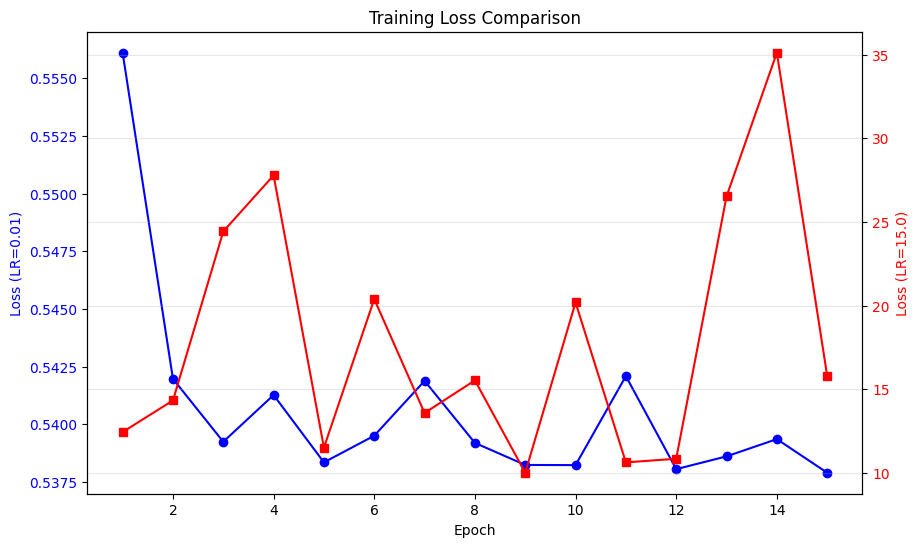


--- Plot the Decision Boundary using the first two features ---


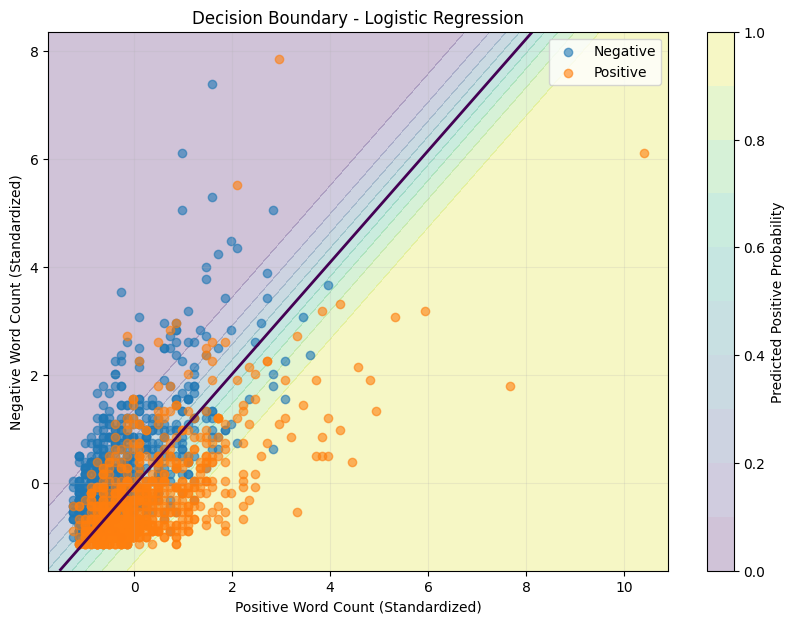


--- Check numerical stability of both training experiments ---

Normal Learning Rate
Weights are finite: True
Bias is finite: True
Loss history is finite: True
Training diverged: False
All parameters and losses are finite.

Large Learning Rate
Weights are finite: True
Bias is finite: True
Loss history is finite: True
Training diverged: False
All parameters and losses are finite.


In [ ]:
# ==============================================================
# Part 2.2 - Learning-rate comparison and decision boundary
# ==============================================================

eta_normal = 0.01
eta_large = 15.0
comparison_epochs = 15

# Generate identical training orders for both experiments
rng = np.random.default_rng(123)
shared_epoch_orders = [rng.permutation(len(X_train)) for _ in range(comparison_epochs)]

# Use identical initial parameters
initial_weights = np.zeros(X_train.shape[1])
initial_bias = 0.0

# TODO: Train Logistic Regression using both learning rates.
# Train the first model using the normal learning rate
print("\n---","\033[1mTrain the first model using the normal learning rate\033[0m","---")
weights_normal, bias_normal, loss_normal, diverged_normal = train_logistic_regression_sgd_each_epoch_loss(
        X=X_train,
        y=y_train,
        learning_rate=eta_normal,
        epochs=comparison_epochs,
        initial_weights=initial_weights,
        initial_bias=initial_bias,
        epoch_orders=shared_epoch_orders
    )

# Train the second model using the large learning rate
print("\n---","\033[1mTrain the second model using the large learning rate\033[0m","---")
weights_large, bias_large, loss_large, diverged_large = train_logistic_regression_sgd_each_epoch_loss(
        X=X_train,
        y=y_train,
        learning_rate=eta_large,
        epochs=comparison_epochs,
        initial_weights=initial_weights,
        initial_bias=initial_bias,
        epoch_orders=shared_epoch_orders
    )

print("\nFinal loss with normal learning rate:",loss_normal[-1])
print("Final loss with large learning rate:",loss_large[-1])

# TODO: Plot and compare the Training Loss curves.
print("\n---","\033[1mPlot and compare the Training Loss curves\033[0m","---")
fig, ax1 = plt.subplots(figsize=(10, 6))

# Model 1
ax1.plot(
    range(1, len(loss_normal)+1),
    loss_normal,
    "o-b",
    label="LR = 0.01"
)
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Loss (LR=0.01)", color="b")
ax1.tick_params(axis="y", labelcolor="b")

# Model 2
ax2 = ax1.twinx()
ax2.plot(
    range(1, len(loss_large)+1),
    loss_large,
    "s-r",
    label="LR = 15.0"
)
ax2.set_ylabel("Loss (LR=15.0)", color="r")
ax2.tick_params(axis="y", labelcolor="r")

plt.title("Training Loss Comparison")
plt.grid(alpha=0.3)

plt.show()

# TODO: Plot the Decision Boundary using the first two features.
print("\n---","\033[1mPlot the Decision Boundary using the first two features\033[0m","---")
# Define the plotting range
x1_min = X_train[:, 0].min() - 0.5
x1_max = X_train[:, 0].max() + 0.5

x2_min = X_train[:, 1].min() - 0.5
x2_max = X_train[:, 1].max() + 0.5

# Create a mesh grid
xx, yy = np.meshgrid(np.linspace(x1_min, x1_max, 300), np.linspace(x2_min, x2_max, 300))
# Keep the remaining four standardized features equal to zero
grid_points = np.zeros((xx.size, X_train.shape[1]))

grid_points[:, 0] = xx.ravel()
grid_points[:, 1] = yy.ravel()

# Predict probabilities using the model trained in Part 2.1
grid_logits = grid_points @ weights + bias
grid_probabilities = sigmoid(grid_logits)
grid_probabilities = grid_probabilities.reshape(xx.shape)

# Draw the decision regions and boundary
plt.figure(figsize=(10, 7))
contour = plt.contourf(
    xx,
    yy,
    grid_probabilities,
    levels=np.linspace(0, 1, 11),
    alpha=0.25
)

plt.colorbar(contour, label="Predicted Positive Probability")
plt.contour(
    xx,
    yy,
    grid_probabilities,
    levels=[0.5],
    linewidths=2
)

# Plot samples from both classes
for class_id, class_name in [(0, "Negative"), (1, "Positive")]:

    mask = y_train == class_id

    plt.scatter(
        X_train[mask, 0],
        X_train[mask, 1],
        label=class_name,
        alpha=0.6
    )

plt.xlabel("Positive Word Count (Standardized)")
plt.ylabel("Negative Word Count (Standardized)")

plt.title("Decision Boundary - Logistic Regression")

plt.legend()
plt.grid(True, alpha=0.2)

plt.show()
# TODO: Analyze the effect of Learning Rate on training stability.
print("\n---","\033[1mCheck numerical stability of both training experiments\033[0m","---")
def check_training_stability(name, weights, bias, loss_history, diverged):
    print(f"\n{name}")
    print("Weights are finite:", np.all(np.isfinite(weights)))
    print("Bias is finite:", np.isfinite(bias))
    print("Loss history is finite:", np.all(np.isfinite(loss_history)))
    print("Training diverged:", diverged)

    if diverged or not (
        np.all(np.isfinite(weights))
        and np.isfinite(bias)
        and np.all(np.isfinite(loss_history))
    ):
        print("Numerical instability detected.")

    else:
        print("All parameters and losses are finite.")
check_training_stability("Normal Learning Rate", weights_normal, bias_normal, loss_normal, diverged_normal)
check_training_stability("Large Learning Rate", weights_large, bias_large, loss_large, diverged_large)


<div dir="rtl" style="box-sizing:border-box; max-width:100%; background-color:#FFF8E7; color:#2B2317; border-right:4px solid #D9A441; border-radius:6px; padding:16px 20px; margin:6px 0; line-height:1.9; text-align:right; overflow-wrap:break-word;">

<b style="color:#8A6116;">پاسخ تشریحی ۲.۲</b>

<p><strong>سؤال.</strong> پدیده‌ی Overshooting چیست؟ چرا Training Loss برای دو مقدار Learning Rate متفاوت رفتار متفاوتی دارد؟ نمودار Decision Boundary چه اطلاعاتی درباره‌ی جداسازی دو Class در فضای دو Feature اول ارائه می‌دهد؟</p>

---

<strong>پاسخ </strong>


<p>
در روش SGD ما هر بار از یک نمونه استفاده می کنیم و با محاسبه لاس، سسعی میکنیم وزن ها را به نوعی تغییر دهیم تا به بهترین ترکیب وزن ها دست یابیم. میزان تغییر هر بار با استفاده از learning rate مشخص می شود، اینکه ما قدم های حرکتمان کوچک باشد یا بزرگ؛ اگر learning rate بزرگ باشد، به جای حرکت تدریجی به سمت نقطه بهینه، در هر بروزرسانی از روی آن عبور می کنیم و به سمت دیگر تابع هزینه پرش می کنیم. پس بجای نزدیک شدن به نقطه مینیمم تابع loss، پارامتر ها دایما اطراف آن نوسان می کنند و یا از آن دور می شوند.
</p>

---

<p>
دلیل رفتار متفاوت training loss برای دو مقدار learning rate هم دقیقا به همان موضوع overshooting بر می گردد؛ در نمودار آبی می بینیم گه loss تقریبا در تمام eepoch ها نزدیک به 0.54 باقیمانده و به تدریج کاهش پیدا کرده، اما در نمودار قرمز loss مدام نوسان می کند و مدام افزایش و کاهش دارد. در مدل دوم مدل فرصت نزدیک شدن به نقظه بهینه را پیدا نمی کند چون هر بار از روی آن پرش می کند و به سمت دیگر نمودار فرضی لاس می رود.
</p>

---

<p>
نمودار Decision Boundary که در سلول بالا هست نشان می‌دهد که مدل Logistic Regression چگونه دو کلاس Positive و Negative را بر اساس دو ویژگی اول از یکدیگر جدا می‌کند.

مشاهده می شود بخشی از نمونه ها به خوبی به دو دسته منفی و مثبت تقسیم شده اند و همچنین
 مرز تصمیم به صورت یک خط مستقیم نمایش داده شده است که نواحی مربوط به هر کلاس را مشخص می‌کند.

 اما در عین حال مشاهده می‌شود که بخشی از نمونه‌های دو کلاس در اطراف این مرز با یکدیگر همپوشانی دارند؛ این نشان می دهد  دو ویژگی اول (تعداد کلمات مثبت و تعداد کلمات منفی) برای جداسازی کامل کلاس‌ها کافی نیستند؛ منطقی هم هست، ما در قسمت های قبل از 6 ویژگی استفاده کردیم که همان ها نیز ممکن است کامل نباشند، اما مدل همچنان قادر است تا حد مناسبی بین آن‌ها تمایز ایجاد کند.
</p>

</div>

---

<div dir="rtl" align="right">

## ۳. ارزیابی شباهت معنایی واژه‌ها و جمله‌ها

در این سؤال با استفاده از بردارهای از پیش آموزش‌دیده‌ی GloVe، شباهت معنایی واژه‌ها و جمله‌ها را محاسبه و با قضاوت انسانی مقایسه می‌کنید. ابتدا توابع محاسبه شباهت را پیاده‌سازی کرده، سپس عملکرد آن‌ها را روی مجموعه‌داده‌های واقعی ارزیابی می‌کنید. در پایان نیز محدودیت‌های این روش‌ها را بررسی خواهید کرد. نیازی به آموزش مدل جدید نیست.

</div>


<div dir="rtl" align="right">

### مجموعه‌داده‌ها و مدل مورد استفاده

در تمام بخش‌های سؤال دوم از بردارهای **GloVe 6B با بُعد ۵۰** استفاده کنید. واژگان این سؤال به ۵۰٬۰۰۰ واژه نخست فایل GloVe محدود است. سلول‌های زیر ۵۰٬۰۰۰ واژه نخست GloVe و مجموعه‌داده‌های موردنیاز را بارگذاری می‌کنند.

- **WordSim-353:** شامل ۳۵۳ جفت‌واژه با امتیاز انسانی از صفر تا ۱۰، با تأکید بر ارتباط معنایی (Relatedness).
- **SimLex-999:** شامل ۹۹۹ جفت‌واژه با امتیاز انسانی از صفر تا ۱۰، با تأکید بر شباهت معنایی (Similarity).
- **STS Benchmark:** شامل جفت‌جمله‌های دارای امتیاز شباهت انسانی. در این تمرین از ۱۳۷۹ جفت‌جمله بخش Test استفاده می‌شود که امتیاز آن‌ها در نسخه مورد استفاده بین صفر و یک است. ستون‌های `sentence1` و `sentence2` متن جملات و ستون `score` امتیاز انسانی را نشان می‌دهند.

از همین داده‌ها و ترتیب سطرهای آن‌ها در ارزیابی استفاده کنید؛ رکوردهای تکراری را حذف نکنید.

</div>


In [ ]:
# ==============================================================
# Question 3 - Model and datasets
# ==============================================================

# Load the first 50,000 pretrained GloVe vectors.
glove_path = "datasets/glove.6B/glove.6B.50d.txt"
similarity_embeddings = {}
glove_ranks = {}

with open(glove_path, encoding="utf-8") as f:
    for index, line in enumerate(f):
        if index >= 50_000:
            break
        word, *values = line.split()
        similarity_embeddings[word] = np.asarray(values, dtype=np.float32)
        glove_ranks[word] = index + 1

assert len(similarity_embeddings) == 50_000
assert all(len(vector) == 50 for vector in similarity_embeddings.values())
print("Vocabulary size:", len(similarity_embeddings))
print("Embedding dimension:", len(next(iter(similarity_embeddings.values()))))

Vocabulary size: 50000
Embedding dimension: 50


In [ ]:
wordsim = pd.read_csv("datasets/wordsim353/combined.csv").iloc[:, :3].copy()
wordsim.columns = ["word1", "word2", "human_score"]
simlex = pd.read_csv("datasets/simlex999/SimLex-999.txt", sep="\t")[["word1", "word2", "SimLex999"]].copy()
simlex.columns = ["word1", "word2", "human_score"]
word_datasets = {"WordSim-353": wordsim, "SimLex-999": simlex}
assert len(wordsim) == 353 and len(simlex) == 999
display(pd.DataFrame({"Dataset": list(word_datasets), "Number of pairs": [len(wordsim), len(simlex)]}))

,Dataset,Number of pairs
0,WordSim-353,353
1,SimLex-999,999


In [ ]:
# Preview the data format, independently of the later error analysis.
word_preview = pd.concat([
    frame.sort_values(["human_score", "word1", "word2"], ascending=[False, True, True]).head(1).assign(Dataset=name)
    for name, frame in word_datasets.items()
])
display(word_preview[["Dataset", "word1", "word2", "human_score"]].reset_index(drop=True))


,Dataset,word1,word2,human_score
0,WordSim-353,tiger,tiger,10.0
1,SimLex-999,vanish,disappear,9.8


In [ ]:
sts_test_pairs = pd.read_csv("datasets/stsb/test.csv")
assert len(sts_test_pairs) == 1379 and sts_test_pairs["score"].between(0, 1).all()
print("Number of sentence pairs:", len(sts_test_pairs))
for preview in sts_test_pairs.head(1).itertuples(index=False):
    print("Sentence 1:", preview.sentence1)
    print("Sentence 2:", preview.sentence2)
    print("Human similarity:", preview.score)

Number of sentence pairs: 1379
Sentence 1: A girl is styling her hair.
Sentence 2: A girl is brushing her hair.
Human similarity: 0.5


<div dir="rtl" align="right">

### ۳.۱ محاسبه Cosine Similarity و Nearest Neighbors

**صورت مسئله**

برای سنجش شباهت بردارهای GloVe، توابع زیر را پیاده‌سازی کنید:

$$\|u\|_2=\sqrt{\sum_i u_i^2},\qquad
\operatorname{cos}(u,v)=\frac{u\cdot v}{\|u\|_2\|v\|_2}.$$

**آنچه باید انجام دهید**

- تابع `vector_norm` را برای محاسبه L2 Norm و تابع `manual_cosine_similarity` را برای محاسبه Cosine Similarity تکمیل کنید.
- با اجرای مثال‌های مشخص‌شده، شباهت بردارهای هم‌جهت، عمود و خلاف‌جهت و اثر تغییر طول بردار بر Dot Product و Cosine را بررسی کنید.
- تابع `find_word_neighbors` را تکمیل کنید تا `k` واژه با بیشترین شباهت Cosine را به‌ترتیب نزولی و در قالب فهرستی از زوج‌های `(word, cosine_score)` برگرداند. واژه ورودی نباید جزو نتایج باشد؛ در صورت برابری امتیازها، ترتیب الفبایی ملاک است.
- پنج همسایه نزدیک واژه‌های `computer` و `science` را به‌همراه امتیاز شباهت نمایش دهید.

**خروجی مورد انتظار**

- نتایج عددی محاسبه Cosine و مقایسه آن با Dot Product.
- جدول نزدیک‌ترین واژه‌ها و امتیاز Cosine آن‌ها.

**نکات و محدودیت‌ها**

- توابع این بخش را با عملیات پایه NumPy پیاده‌سازی کنید؛ استفاده از توابع آماده محاسبه Norm، Cosine یا Nearest Neighbors مجاز نیست.
- برای ورودی‌های نامعتبر، ابعاد ناسازگار و بردار صفر در محاسبه Cosine، `ValueError` ایجاد کنید. در محاسبه Norm، خروجی بردار صفر باید صفر باشد.
- در `find_word_neighbors`، واژه ورودی را پس از حذف فاصله‌های ابتدا و انتها و تبدیل به حروف کوچک بررسی کنید. برای واژه ناشناخته یا مقدار نامعتبر `k`، `ValueError` ایجاد کنید. مقدار `k` باید عدد صحیح مثبت (به‌جز `bool`) و حداکثر برابر تعداد همسایه‌های معتبر باشد.

</div>


In [ ]:
# ==============================================================
# Part 3.1 - Vector similarity and nearest neighbors
# ==============================================================

def vector_norm(vector):
    scale = np.max(np.abs(vector))

    if scale == 0:
        return 0.0

    scaled_vector = vector / scale
    norm = scale * np.sqrt(np.sum(scaled_vector * scaled_vector))

    if not np.isfinite(norm):
        raise ValueError("The calculated norm is not finite.")

    return float(norm)

In [ ]:
# Validate and convert a vector into a one-dimensional numeric array
def validate_vector(vector, name="vector"):

    if vector is None:
        raise ValueError(f"{name} cannot be None.")

    try:
        arr = np.asarray(vector)
    except (TypeError, ValueError):
        raise ValueError(f"{name} must be a valid numeric vector.")

    # Check vector dimensions and data type
    if arr.ndim != 1 or arr.size == 0:
        raise ValueError(f"{name} must be a non-empty one-dimensional vector.")

    if not np.issubdtype(arr.dtype, np.number):
        raise ValueError(f"{name} must contain numeric values.")

    if np.issubdtype(arr.dtype, np.complexfloating):
        raise ValueError(f"{name} must contain real values.")

    arr = arr.astype(np.float64, copy=False)

    # Reject NaN and Infinity values
    if not np.all(np.isfinite(arr)):
        raise ValueError(f"{name} must contain only finite values.")

    return arr

In [ ]:
def manual_cosine_similarity(u, v):
    # Validate input vectors
    u = validate_vector(u, name="u")
    v = validate_vector(v, name="v")

    # Check whether both vectors have the same dimensions
    if u.shape != v.shape:
        raise ValueError("Both vectors must have the same dimensions.")

    # Calculate the L2 norm of each vector
    norm_u = vector_norm(u)
    norm_v = vector_norm(v)

    # Cosine similarity is undefined for zero vectors
    if norm_u == 0 or norm_v == 0:
        raise ValueError("Cosine similarity is undefined for zero vectors.")

    # Normalize both vectors
    u_normalized = u / norm_u
    v_normalized = v / norm_v

    # Calculate cosine similarity using the dot product
    similarity = np.sum(u_normalized * v_normalized)

    # Limit small floating-point errors
    similarity = np.clip(similarity, -1.0, 1.0)

    return float(similarity)

In [ ]:
# Verify basic cases and display the computed values.
assert np.isclose(vector_norm([3., 4.]), 5.)
cosine_checks = pd.DataFrame([
    {"Case": "Same direction", "Cosine": manual_cosine_similarity([1, 0], [2, 0])},
    {"Case": "Orthogonal", "Cosine": manual_cosine_similarity([1, 0], [0, 1])},
    {"Case": "Opposite direction", "Cosine": manual_cosine_similarity([1, 0], [-1, 0])},
])
assert np.allclose(cosine_checks["Cosine"], [1, 0, -1])
display(cosine_checks)


,Case,Cosine
0,Same direction,1.0
1,Orthogonal,0.0
2,Opposite direction,-1.0


In [ ]:
# Scaling changes the dot product but preserves cosine.
u, v = np.array([1., 2.]), np.array([2., 1.])
scaling_comparison = pd.DataFrame([
    {"Vectors": "u and v", "Dot product": float(u @ v), "Cosine": manual_cosine_similarity(u, v)},
    {"Vectors": "10*u and v", "Dot product": float((10*u) @ v), "Cosine": manual_cosine_similarity(10*u, v)},
])
display(scaling_comparison)


,Vectors,Dot product,Cosine
0,u and v,4.0,0.8
1,10*u and v,40.0,0.8


In [ ]:
# Check vector validity without assigning an artificial cosine to zero vectors.
def is_valid_embedding(vector):
    if vector is None:
        return False
    try:
        return vector_norm(vector) > 0
    except (ValueError, TypeError):
        return False

In [ ]:
def find_word_neighbors(word, embeddings, k=5):
    if not isinstance(word, str):
      raise ValueError("The input word must be a string.")
    query_word = word.strip().lower()
    if not query_word:
      raise ValueError("The input word cannot be empty.")
    # Validate k
    if isinstance(k, (bool, np.bool_)) or not isinstance(k, (int, np.integer)):
        raise ValueError("k must be a positive integer.")
    if k <= 0:
        raise ValueError("k must be greater than zero.")
    # Validate the embeddings dictionary
    if embeddings is None or not hasattr(embeddings, "items"):
        raise ValueError("Embeddings must be a dictionary-like object.")
# Create a lookup using normalized word keys
    normalized_embeddings = {}

    for embedding_word, embedding_vector in embeddings.items():

        if not isinstance(embedding_word, str):
            continue

        normalized_word = embedding_word.strip().lower()

        if normalized_word and normalized_word not in normalized_embeddings:
            normalized_embeddings[normalized_word] = embedding_vector

    # Check whether the query word exists
    if query_word not in normalized_embeddings:
        raise ValueError(f"Unknown word: {query_word}")

    # Validate the query embedding
    query_vector = validate_vector(normalized_embeddings[query_word], name="query embedding")
    query_norm = vector_norm(query_vector)

    if query_norm == 0:
        raise ValueError("The query word has an invalid zero embedding.")

    # Normalize the query vector
    query_unit = query_vector / query_norm

    candidate_words = []
    candidate_unit_vectors = []

    # Collect valid candidate embeddings
    for candidate_word, candidate_vector in normalized_embeddings.items():
        # Exclude the query word itself
        if candidate_word == query_word:
            continue

        # Skip invalid embeddings
        if not is_valid_embedding(candidate_vector):
            continue

        try:
            candidate_array = validate_vector(candidate_vector)
        except (ValueError, TypeError):
            continue

        # Skip embeddings with incompatible dimensions
        if candidate_array.shape != query_vector.shape:
            continue

        candidate_norm = vector_norm(candidate_array)

        if candidate_norm == 0:
            continue

        # Normalize the candidate embedding
        candidate_unit = candidate_array / candidate_norm

        candidate_words.append(candidate_word)
        candidate_unit_vectors.append(candidate_unit)

    # Check whether enough valid neighbors are available
    if k > len(candidate_words):
        raise ValueError(
            f"k={k} exceeds the number of valid neighbors "
            f"({len(candidate_words)})."
        )

    # Calculate cosine similarities
    candidate_matrix = np.vstack(candidate_unit_vectors)
    similarities = candidate_matrix @ query_unit

    # Limit floating-point errors
    similarities = np.clip(similarities, -1.0, 1.0)

    # Create word-score pairs
    results = [
        (candidate_words[i], float(similarities[i]))
        for i in range(len(candidate_words))
    ]

    # Sort by descending similarity and alphabetical order
    results.sort(key=lambda item: (-item[1], item[0]))

    # Return the top k neighbors
    return results[:k]

In [ ]:
neighbor_rows = []
for query in ("computer", "science"):
    neighbors = find_word_neighbors(query, similarity_embeddings, k=5)
    print("Query:", query)
    display(pd.DataFrame(neighbors, columns=["Neighbor", "Cosine"]).round(4))
    neighbor_rows.extend({"word": query, "neighbor": word, "cosine_score": score} for word, score in neighbors)
neighbor_results = pd.DataFrame(neighbor_rows)


Query: computer


,Neighbor,Cosine
0,computers,0.9165
1,software,0.8815
2,technology,0.8526
3,electronic,0.8126
4,internet,0.8060


Query: science


,Neighbor,Cosine
0,sciences,0.8548
1,research,0.8437
2,institute,0.8386
3,studies,0.8369
4,physics,0.8314


<div dir="rtl" style="box-sizing:border-box; max-width:100%; background-color:#FFF8E7; color:#2B2317; border-right:4px solid #D9A441; border-radius:6px; padding:16px 20px; margin:6px 0; line-height:1.9; text-align:right; overflow-wrap:break-word;">

<b style="color:#8A6116;">پاسخ تشریحی ۳.۱</b>

<p><strong>سؤال ۱.</strong> چرا Dot Product به‌تنهایی معیار مناسبی برای مقایسه شباهت بردارها نیست؟ پاسخ را با نتایج مثال عددی توضیح دهید.</p>

<p><strong>سؤال ۲.</strong> آیا نزدیک‌ترین همسایه‌های برداری یک واژه لزوماً مترادف آن هستند؟ با یک مثال از خروجی خود توضیح دهید.</p>

---

<strong>پاسخ سوال 1</strong>

<p>
Dot Product به این دلیل معیار مناسبی برای مقایسه شباهت بردار ها نیست که علاوه بر جهت بردارها، بصورت مستقیم به اندازه بردار ها نیز وابسته است.

بعنوان مثال، در یکی از سلول های بالا، دیدیم دو بردار u=[1,2] و v=[2,1] داشتیم و ضرب داخلی آن برابر 4 شد، اما هنگامیکه عناصر بردار u را 10 برابر کردیم (فقط اندازه آنرا تغییر دادیم و جهتش را ثابت نگه داشتیم) ضرب داخلی آن با بردار v برابر 40 شد، یعنی  10 برابر؛ در حالیکه زاویه بین دو بردار همچنان ثابت بود.

در مقابل، Cosine Similarity بر مبنای زاویه بین دو بردار است و چون بر اساس طول بردار ها نرمال می شود، دیگر مشکل ضرب داخلی را ندارد؛ در مثال بالا نیز مشخص شد با 10 برابر کردن اندازه یکی از بردار ها، Cosine زاویه بین دو بردار ثابت باقی ماند.
</p>

---

<strong>پاسخ سوال 2</strong>

<p>
خیر - Glove (و حتی SGNS) واژه ها را بر اساس اینکه چقدر با هم رخ می دهند و چقدر در context های مشابه به کار می روند به فضای برداری تبدیل می کند. پس ممکن است دو واژه در بسیاری از متن ها در زمینه های مشابه استفاده شوند، اما مترادف نباشند.

در خروجی سلول آخر هم مشاهده می شود که در 5 همسایه اول واژه computer,کلمات software, technology, electronic و internet حضور دارند که هیچکدام با واژه computer مترادف نیستند، همچنین در همسایگی واژه sciense، واژگان research, institue, studies و physics دیده می شود که آنها هم مترادف واژه sciense نیستند، بلکه در یک حوزه موضوعی با آن قرار می گیرند.
</p>

</div>


<div dir="rtl" align="right">

### ۳.۲ ارزیابی Word Similarity

**صورت مسئله**

در این بخش، امتیازهای شباهت GloVe را با امتیازهای انسانی در **WordSim-353** و **SimLex-999** مقایسه کنید. برای ارزیابی از ضریب **Spearman Correlation** استفاده می‌شود که میزان توافق رتبه‌بندی دو مجموعه امتیاز را اندازه می‌گیرد:

$$\rho=\operatorname{corr}(\operatorname{rank}(\mathrm{human}),\operatorname{rank}(\mathrm{model})).$$

مقدار نزدیک به ۱ نشان‌دهنده توافق رتبه‌ای بیشتر است. پیاده‌سازی این معیار لازم نیست.

**آنچه باید انجام دهید**

- تابع `evaluate_word_similarity` را تکمیل کنید تا برای جفت‌واژه‌های معتبر، Cosine Similarity را محاسبه و موارد خارج از واژگان (OOV) یا نامعتبر را جدا کند.
- خروجی تابع باید شامل `(summary, scores, rejected)` باشد. در `summary` تعداد کل جفت‌ها (`N_total`)، تعداد معتبر (`N_valid`)، تعداد دارای OOV (`OOV_pairs`)، سایر موارد نامعتبر (`Other_invalid`) و نسبت پوشش (`Coverage`) را ثبت کنید. جدول `scores` نیز باید ستون `cosine` را داشته باشد.
- با استفاده از تابع `safe_spearman`، همبستگی رتبه‌ای هر مجموعه‌داده را در ستون `Spearman_rho` محاسبه کرده و نتایج را در یک نمودار ستونی مقایسه کنید.
- تابع `normalized_ranks` را تکمیل کنید. رتبه مقادیر را با روش میانگین برای مقادیر مساوی محاسبه کرده و سپس با رابطه $(r-1)/(n-1)$ به بازه صفر تا یک تبدیل کنید. برای ورودی با کمتر از دو مقدار، آرایه‌ای هم‌اندازه شامل `NaN` برگردانید.
- نمونه‌های مشخص‌شده در نوت‌بوک را از نتایج استخراج کنید و اختلاف رتبه شباهت مدل و امتیاز انسانی را بررسی کنید.

**خروجی مورد انتظار**

- جدول تعداد جفت‌های معتبر و نامعتبر، Coverage و Spearman برای هر مجموعه‌داده.
- نمودار مقایسه Spearman و جدول نمونه‌های انتخاب‌شده همراه با امتیازها و رتبه‌ها.

**نکات و محدودیت‌ها**

- فقط جفت‌هایی را ارزیابی کنید که هر دو واژه دارای بردار معتبر باشند. پوشش برابر نسبت جفت‌های معتبر به کل جفت‌هاست.
- امتیاز انسانی و Cosine مقیاس یکسانی ندارند؛ برای تحلیل نمونه‌ها از رتبه‌های نرمال‌شده محاسبه‌شده استفاده کنید، نه اختلاف مستقیم این دو امتیاز.

</div>


In [ ]:
# ==============================================================
# Part 3.2 - Word similarity evaluation
# ==============================================================

# Prepare word pairs; keep original row IDs and count exclusion reasons.
def prepare_word_pairs(pairs, embeddings):
    valid, rejected = [], []
    for row_id, row in enumerate(pairs.itertuples(index=False)):
        w1, w2 = str(row.word1).strip().lower(), str(row.word2).strip().lower()
        score = float(pd.to_numeric(row.human_score, errors="coerce"))
        item = dict(row_id=row_id, word1=w1, word2=w2, human_score=score)
        if w1 not in embeddings or w2 not in embeddings:
            item["reason"] = "OOV"
        elif not np.isfinite(score) or not is_valid_embedding(embeddings[w1]) or not is_valid_embedding(embeddings[w2]):
            item["reason"] = "Invalid"
        else:
            valid.append(item)
            continue
        rejected.append(item)
    columns = ["row_id", "word1", "word2", "human_score"]
    return pd.DataFrame(valid, columns=columns), pd.DataFrame(rejected, columns=columns+["reason"])


In [ ]:
def evaluate_word_similarity(pairs, embeddings):
    # Separate valid and rejected word pairs
    valid_pairs, rejected = prepare_word_pairs(pairs, embeddings)

    scores_list = []
    invalid_list = []

    # Calculate cosine similarity for valid pairs
    for row in valid_pairs.to_dict("records"):
        word1 = row["word1"]
        word2 = row["word2"]
        try:
            cosine = manual_cosine_similarity(embeddings[word1], embeddings[word2])
            scores_list.append({**row, "cosine": cosine})
        except (ValueError, TypeError, OverflowError):
            invalid_list.append({**row, "reason": "Invalid"})

    # Create the score and rejection tables
    scores = pd.DataFrame(scores_list, columns=["row_id", "word1", "word2", "human_score", "cosine"])
    extra_invalid = pd.DataFrame(invalid_list,columns=["row_id", "word1", "word2", "human_score", "reason"])
    rejected = pd.concat([rejected, extra_invalid], ignore_index=True)

    # Calculate evaluation statistics
    n_total = len(pairs)
    n_valid = len(scores)

    oov_pairs = int((rejected["reason"] == "OOV").sum())
    other_invalid = int((rejected["reason"] == "Invalid").sum())

    if n_total > 0:
      coverage = (n_valid / n_total)
    else:
      coverage = 0.0

    summary = {"N_total": n_total, "N_valid": n_valid, "OOV_pairs": oov_pairs, "Other_invalid": other_invalid, "Coverage": coverage}
    return summary, scores, rejected


In [ ]:
word_results, word_rejections, word_summary_records = {}, {}, []
for dataset_name, pairs in word_datasets.items():
    summary, scores, rejected = evaluate_word_similarity(pairs, similarity_embeddings)
    word_results[dataset_name], word_rejections[dataset_name] = scores, rejected
    word_summary_records.append({"Dataset": dataset_name, **summary})
word_summary_table = pd.DataFrame(word_summary_records)
coverage_report = word_summary_table[["Dataset", "N_total", "N_valid", "OOV_pairs", "Other_invalid"]].copy()
coverage_report.columns = ["Dataset", "Total", "Evaluated", "OOV", "Invalid"]
coverage_report["Coverage (%)"] = (100*word_summary_table["Coverage"]).round(2)
display(coverage_report)

/tmp/ipykernel_3542/2759938546.py:21: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  rejected = pd.concat([rejected, extra_invalid], ignore_index=True)
/tmp/ipykernel_3542/2759938546.py:21: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  rejected = pd.concat([rejected, extra_invalid], ignore_index=True)


,Dataset,Total,Evaluated,OOV,Invalid,Coverage (%)
0,WordSim-353,353,348,5,0,98.58
1,SimLex-999,999,995,4,0,99.60


In [ ]:
# Spearman is provided; it ranks tied values using average ranks.
def safe_spearman(human, model):
    human, model = np.asarray(human, dtype=float), np.asarray(model, dtype=float)
    if len(human) < 2:
        return np.nan, "fewer_than_two_pairs"
    if not np.isfinite(human).all() or not np.isfinite(model).all():
        return np.nan, "nonfinite_scores"
    if np.all(human == human[0]) or np.all(model == model[0]):
        return np.nan, "constant_scores"
    return float(spearmanr(human, model).statistic), "ok"


# Compute Spearman correlation for each word dataset.
word_summary_table["Spearman_rho"] = np.nan
word_summary_table["Spearman_status"] = ""

for i, row in word_summary_table.iterrows():
    dataset_name = row["Dataset"]
    scores = word_results[dataset_name]
    rho, status = safe_spearman(scores["human_score"], scores["cosine"])

    word_summary_table.loc[i, "Spearman_rho"] = rho
    word_summary_table.loc[i, "Spearman_status"] = status

display(word_summary_table[["Dataset", "N_valid", "Spearman_rho"]].rename(
    columns={"N_valid": "Evaluated pairs", "Spearman_rho": "Spearman (rho)"}).round(4))

,Dataset,Evaluated pairs,Spearman (rho)
0,WordSim-353,348,0.5247
1,SimLex-999,995,0.2652


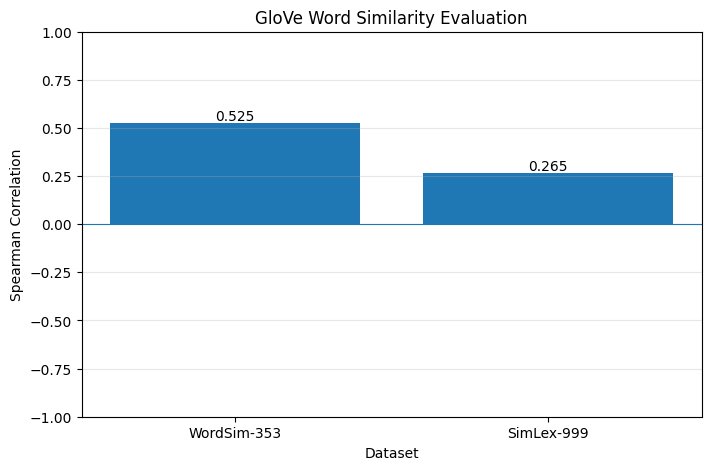

In [ ]:
# Plot the two word-level Spearman correlations.
plt.figure(figsize=(8, 5))
plot_data = word_summary_table.dropna(subset=["Spearman_rho"])
bars = plt.bar(plot_data["Dataset"], plot_data["Spearman_rho"])

plt.ylabel("Spearman Correlation")
plt.xlabel("Dataset")
plt.title("GloVe Word Similarity Evaluation")

plt.ylim(-1, 1)
plt.axhline(0, linewidth=0.8)

# Display the correlation values above each bar
for bar in bars:
    value = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value,
        f"{value:.3f}",
        ha="center",
        va="bottom" if value >= 0 else "top"
    )

plt.grid(axis="y", alpha=0.3)
plt.show()

In [ ]:
# Compare ranks rather than subtracting scores on different scales.
def normalized_ranks(values):
    # Convert the input into a NumPy array
    values = np.asarray(values, dtype=float)

    # Check the input dimension
    if values.ndim != 1:
        raise ValueError("Input must be a one-dimensional array.")

    n = len(values)
    if n < 2:
        return np.full(n, np.nan)

    # Calculate ranks using average method for tied values
    ranks = pd.Series(values).rank(method="average").to_numpy()

    # Normalize ranks to the range [0, 1]
    normalized = (ranks - 1) / (n - 1)
    return normalized

In [ ]:
# Mine overestimation cases using ranks over the entire valid dataset.
def find_word_error_candidates(scores, k=10):
    if isinstance(k, bool) or not isinstance(k, (int, np.integer)) or k < 1:
        raise ValueError("k must be a positive integer")
    ranked = scores.copy()
    ranked["human_rank"] = normalized_ranks(ranked["human_score"])
    ranked["model_rank"] = normalized_ranks(ranked["cosine"])
    ranked["overestimation"] = ranked["model_rank"] - ranked["human_rank"]
    ranked["rank_gap"] = ranked["overestimation"].abs()
    eligible = ranked[(ranked["human_rank"] <= .30) & (ranked["model_rank"] >= .70)]
    status, rule = "strict", "human rank <= 0.30; model rank >= 0.70"
    if eligible.empty:
        eligible = ranked[ranked["overestimation"] > 0]
        status, rule = "fallback_positive", "positive model-minus-human rank"
    if eligible.empty:
        status = "empty"
    top = eligible.sort_values(["overestimation", "word1", "word2", "human_score", "cosine"],
                               ascending=[False, True, True, True, True], kind="mergesort").head(k).copy()
    top["candidate_rank"] = np.arange(1, len(top)+1)
    info = dict(Status=status, Selection=rule, Eligible=len(eligible), Returned=len(top))
    return top.reset_index(drop=True), info


In [ ]:
word_candidates, word_selection_records = {}, []
for dataset_name, scores in word_results.items():
    candidates, info = find_word_error_candidates(scores, k=10)
    word_candidates[dataset_name] = candidates
    word_selection_records.append({"Dataset": dataset_name, **info})
word_selection_report = pd.DataFrame(word_selection_records)
print("Candidate pools: largest overestimation within the reported selection rule")
display(word_selection_report)


Candidate pools: largest overestimation within the reported selection rule


,Dataset,Status,Selection,Eligible,Returned
0,WordSim-353,strict,human rank <= 0.30; model rank >= 0.70,14,10
1,SimLex-999,strict,human rank <= 0.30; model rank >= 0.70,70,10


In [ ]:
# Select the highest-priority available candidate for each dataset.
selected_words = []
for name, candidates in word_candidates.items():
    if candidates.empty:
        print(f"No analysis candidate available for {name}; skipped.")
        continue
    selected_words.append({**candidates.iloc[0].to_dict(), "Dataset": name})

word_examples = pd.DataFrame(selected_words, columns=[
    "row_id", "word1", "word2", "human_score", "cosine", "human_rank", "model_rank",
    "overestimation", "rank_gap", "candidate_rank", "Dataset",
])


In [ ]:
display(word_examples[["Dataset", "word1", "word2", "human_score", "cosine"]].rename(
    columns={"human_score": "Human score", "cosine": "Cosine"}).round(4))
display(word_examples[["Dataset", "candidate_rank", "human_rank", "model_rank", "rank_gap"]].rename(
    columns={"candidate_rank": "Candidate rank", "human_rank": "Human rank",
             "model_rank": "Model rank", "rank_gap": "Rank gap"}).round(4))


,Dataset,word1,word2,Human score,Cosine
0,WordSim-353,wednesday,news,2.22,0.7454
1,SimLex-999,easy,difficult,0.58,0.8345


,Dataset,Candidate rank,Human rank,Model rank,Rank gap
0,WordSim-353,1,0.0749,0.8818,0.8069
1,SimLex-999,1,0.0573,0.9346,0.8773


<div dir="rtl" style="box-sizing:border-box; max-width:100%; background-color:#FFF8E7; color:#2B2317; border-right:4px solid #D9A441; border-radius:6px; padding:16px 20px; margin:6px 0; line-height:1.9; text-align:right; overflow-wrap:break-word;">

<b style="color:#8A6116;">پاسخ تشریحی ۳.۲</b>

<p><strong>سؤال ۱.</strong> دو نمونه انتخاب‌شده چه اختلافی میان رتبه‌بندی مدل و انسان نشان می‌دهند؟ برای هر نمونه یک توضیح احتمالی ارائه دهید.</p>

<p><strong>سؤال ۲.</strong> تفاوت Semantic Similarity و Semantic Relatedness چیست؟ با توجه به این تفاوت، نتایج دو مجموعه‌داده را مقایسه کنید. آیا واژه‌های متضاد نیز می‌توانند شباهت برداری بالایی داشته باشند؟ چرا؟</p>


---

<strong>پاسخ سوال 1</strong>

<p>
در دیتاست WordSim-353 دو واژه news   و Wednesday را داریم که مدل امتیاز 0.7454 و ارزیاب انسانی امتیاز 2.22 را به آن داده است.

در ارزیابی انسانی، این دو واژه از نظر معنایی واژه های مشابهی به حساب نمی آیند؛ اما مدل این دو واژه را بسیار نزدیک تشخیص داده است.

علت احتمالی ان است که در متون خبری، این دو واژه به طور مکرر با هم ظاهر شده اند.، مثلا عبارت هایی مثل Wednesday News، News on Wednesday و ...

مدل های مبتنی بر Co-occurance هم بیشتر روی شباهت آماری تکیه دارند. پس چون این دو واژه احتمالا اغلب در زمینه های مشترک دیده شده اند، بردارهایشان نزدیک به هم شده است.
</p>

<p>
در رابطه با دو واژه easy , difficult هم چنین نتیجه ای می توان گرفت. این دو واژه چون متضاد هستند، ارزیاب انسانی امتیاز بالایی به آنها نداده است اما در مدل ما، چون ملاک، Co-occurance و حضور در زمینه های مشابه هست و این دو واژه نیز با اینکه متضاد هستند، اما ارتباط خوبی در این زمینه با هم دارند، مدل ، امتیاز بالایی به آنها داده است.
</p>


---

<strong>پاسخ سوال 2</strong>

<p>
Semantic Similarity به میزان مشابه بودن معنای دو واژه اشاره دارد. مثلا واژه های (car, automobile) از نظر مفهومی تقریبا یکسان هستند پس Semantically Similar هستند.

اما Semantic Relatedness موضوع کلی تری است و هر نوع رابطه معنایی بین دو واژه را شامل می شود، حتی اگر هم معنی هم نباشند. مثلا واژگان (doctor, hospital) یا (school, teacher) Semantically Related هستند. این واژگان در بیشتر اوقات در یک حوزه یا زمینه مشترک قرار دارند.
</p>

<p>
دیتاست WordSim-353همانطور که در صورت سوال هم گفته شد بیشتر Relatedness را می سنجد، پس اگر دو واژه در یک زمینه مشترک ظاهر شوند، امتیاز نسبتا خوبی می گیرند.

اما دیتاست SimLex-999 بطور خاص برای سنجش Similarity طراحی شده است. در این دیتاست، شباهت معنایی اهمیت دارد، پس مثلا واژگان easy , difficult چون متضاد هستند، امتیاز نسبتا پایین 0.58 را دریافت کرده اند.
</p>


<p>
واژه های متضاد هم می توانند شباهت برداری بالایی داشته باشندچون معمولا در نوع جملات و زمینه های استفاده مشترک هستند، پس مدل از روی زمینه تشخیص می دهد که این کلمات نقش مشابهی دارند و آن را ها نزدیک به هم نگاشت می کند، در خروجی های مدل هم می بینیم که easy و difficult از نظر انسانی شباهت کمی دارند، اما مدل شباهت زیادی برای آنها تشخیص داده است.
</p>
</div>


<div dir="rtl" align="right">

### ۳.۳ ساخت بردار جمله و ارزیابی Sentence Similarity

**صورت مسئله**

با استفاده از بردارهای GloVe، برای هر جمله یک بردار بسازید و دو روش **Mean Pooling** و **Rank-Weighted Pooling** را روی STS Benchmark مقایسه کنید:

$$s_{\mathrm{mean}}=\frac{1}{n}\sum_{i=1}^{n}e(w_i),\qquad
s_{\mathrm{weighted}}=\frac{\sum_{i=1}^{n}\ln(r(w_i))\,e(w_i)}{\sum_{i=1}^{n}\ln(r(w_i))}.$$

در این روابط، $n$ تعداد توکن‌های دارای بردار معتبر و $r(w_i)$ رتبه واژه در ترتیب اصلی فایل GloVe (از ۱) است.

**آنچه باید انجام دهید**

- توابع `mean_sentence_embedding` و `weighted_sentence_embedding` را تکمیل کنید و نتایج آن‌ها را با مثال‌های عددی موجود بررسی کنید. پیش‌پردازش جملات با تابع `tokenize_sentence` انجام می‌شود.
- تابع `score_sentence_pairs` را تکمیل کنید تا شباهت Cosine دو روش را برای جفت‌جمله‌ها محاسبه کند. خروجی `(common, valid_counts)` باشد؛ `common` شامل `row_id`، دو جمله، `gold_score`، `cosine_mean` و `cosine_weighted` و `valid_counts` شامل تعداد جفت‌های معتبر هر روش با کلیدهای `mean` و `weighted` است.
- تابع `evaluate_sts` را تکمیل کنید تا برای هر روش تعداد جفت‌های معتبر، Coverage و Spearman را گزارش کند. خروجی آن `(summary, common)` است؛ `summary` برای هر روش باید ستون‌های `Method`، `N_total`، `N_valid_own`، `N_valid_common`، `Excluded_common`، `Coverage_common` و `Spearman_rho` را داشته باشد.
- دو نمودار پراکندگی برای مقایسه امتیاز انسانی و Cosine رسم کنید. بازه محورهای دو نمودار یکسان باشد.
- تابع `sentence_weight_details` را تکمیل کنید تا برای هر واژه دارای بردار معتبر، تعداد تکرار، رتبه آن در GloVe، مقدار `ln(rank)` و سهم آن از مجموع وزن‌ها را به درصد محاسبه کند. در محاسبه سهم وزن، تعداد تکرار هر واژه را لحاظ کنید. اگر مجموع وزن‌ها صفر بود، سهم وزن را `NaN` در نظر بگیرید.
- نمونه‌های انتخاب‌شده در نوت‌بوک را بررسی کنید: یک نمونه دارای OOV، یک نمونه با نتیجه بهتر در روش وزن‌دار و یک نمونه با نتیجه ضعیف‌تر. جدول سهم وزن واژه‌ها را نیز تحلیل کنید.

**خروجی مورد انتظار**

- نتایج دو روش Pooling و جدول وزن واژه‌ها.
- جدول Coverage و Spearman، تعداد توکن‌های OOV و دو نمودار پراکندگی.
- مقایسه و تحلیل سه جفت‌جمله انتخاب‌شده براساس امتیازهای انسانی، رتبه‌ها و اثر وزن‌دهی.

**نکات و محدودیت‌ها**

- واژه‌های تکراری را حفظ کنید و توکن‌های OOV را در میانگین‌گیری لحاظ نکنید. بردارهای واژه‌ها را پیش از تجمیع نرمال نکنید.
- در روش وزن‌دار از $\ln(r(w))$ استفاده کنید. در صورت نبود واژه معتبر، صفرشدن مجموع وزن‌ها یا نامعتبر بودن بردار نهایی، `None` برگردانید.
- جفتی معتبر مشترک است که امتیاز انسانی آن متناهی باشد و هر دو روش برای هر دو جمله بردار معتبر (غیر از `None`) تولید کنند. Spearman هر دو روش را فقط روی این جفت‌ها محاسبه کنید؛ برای موارد نامعتبر Cosine صفر در نظر نگیرید.
- در جدول `summary`، مقدار `Method` باید `Mean` یا `Rank-Weighted` باشد. `N_total` تعداد کل جفت‌ها، `N_valid_own` تعداد جفت‌های معتبر هر روش به‌تنهایی و `N_valid_common` تعداد جفت‌های معتبر مشترک است. همچنین `Excluded_common = N_total - N_valid_common` و `Coverage_common = N_valid_common / N_total` (بین صفر و یک) است. `Spearman_rho` نیز با تابع بخش ۲.۲ روی جفت‌های مشترک محاسبه شود.
- در خروجی `common`، شناسه `row_id` شماره سطر اصلی مجموعه‌داده از صفر است؛ ترتیب سطرها حفظ شود.
- خروجی `sentence_weight_details` یک DataFrame با ستون‌های `Token`، `Count`، `GloVe rank`، `ln(rank)` و `Weight share (%)` به همین ترتیب است. واژه‌های OOV یا دارای بردار نامعتبر را لحاظ نکنید و ترتیب سطرها را مطابق اولین وقوع واژه‌ها در جمله حفظ کنید.

</div>


In [ ]:
# ==============================================================
# Part 3.3 - Sentence similarity evaluation
# ==============================================================

def tokenize_sentence(sentence):
    return re.findall(r"[a-z]+(?:'[a-z]+)?", sentence.lower())

sentence = "A student reads books."
print("Sentence:", sentence)
display(pd.DataFrame({"Token": tokenize_sentence(sentence),
                      "Has GloVe vector": [word in similarity_embeddings for word in tokenize_sentence(sentence)]}))


Sentence: A student reads books.


,Token,Has GloVe vector
0,a,True
1,student,True
2,reads,True
3,books,True


In [ ]:
# Get a valid word embedding
def get_valid_word_vector(word, embeddings, expected_dim=None):
    if word not in embeddings:
        return None
    try:
        vector = np.asarray(embeddings[word], dtype=float)

        # Check vector dimensions and values
        if vector.ndim != 1 or len(vector) == 0:
            return None

        if not np.all(np.isfinite(vector)):
            return None

        if expected_dim is not None and len(vector) != expected_dim:
            return None

        # Reject zero vectors
        if vector_norm(vector) == 0:
            return None

        return vector

    except (ValueError, TypeError, OverflowError):
        return None

In [ ]:
def mean_sentence_embedding(sentence, embeddings):
    # Build a sentence vector using mean pooling.
    tokens = tokenize_sentence(sentence)
    vectors = []
    expected_dim = None

    for word in tokens:
        vector = get_valid_word_vector(word, embeddings, expected_dim)
        if vector is None:
            continue
        if expected_dim is None:
            expected_dim = len(vector)

        vectors.append(vector)

    # Return None if no valid word vectors exist
    if len(vectors) == 0:
        return None

    # Calculate the mean of word vectors
    sentence_vector = np.mean(vectors, axis=0)

    # Validate the final sentence vector
    if not np.all(np.isfinite(sentence_vector)):
        return None

    if vector_norm(sentence_vector) == 0:
        return None

    return sentence_vector

In [ ]:
# A repeated token contributes once for each occurrence.
toy_embeddings = {"cat": np.array([2., 0.]), "dog": np.array([0., 2.])}
mean_checks = pd.DataFrame([
    {"Sentence": text, "Mean vector": mean_sentence_embedding(text, toy_embeddings)}
    for text in ("cat dog", "cat cat dog", "cat unknown", "unknown")
])
mean_checks["Mean vector"] = mean_checks["Mean vector"].map(lambda vector: np.round(vector, 4) if vector is not None else None)
display(mean_checks)
assert np.allclose(mean_sentence_embedding("cat cat dog", toy_embeddings), [4/3, 2/3])
assert mean_sentence_embedding("unknown", toy_embeddings) is None


,Sentence,Mean vector
0,cat dog,"[1.0, 1.0]"
1,cat cat dog,"[1.3333, 0.6667]"
2,cat unknown,"[2.0, 0.0]"
3,unknown,None


In [ ]:
def weighted_sentence_embedding(sentence, embeddings, rank_map):
    # Build a sentence vector using ln(original GloVe rank) weights.
    tokens = tokenize_sentence(sentence)
    weighted_vectors = []
    weights = []
    expected_dim = None

    for word in tokens:
        vector = get_valid_word_vector(word, embeddings, expected_dim)
        if vector is None:
            continue
        # Get the original GloVe rank
        if word not in rank_map:
            continue
        rank = rank_map[word]

        # Validate the rank
        if (
            isinstance(rank, (bool, np.bool_))
            or not isinstance(rank, (int, float, np.integer, np.floating))
            or not np.isfinite(rank)
            or rank < 1
        ):
            continue

        # Calculate the logarithmic weight
        weight = np.log(rank)

        # Store the vector and its weight
        if expected_dim is None:
            expected_dim = len(vector)

        weighted_vectors.append(vector)
        weights.append(weight)

    # Return None if no valid vectors exist
    if len(weighted_vectors) == 0:
        return None

    # Calculate the total weight
    total_weight = np.sum(weights)

    # Avoid division by zero
    if not np.isfinite(total_weight) or total_weight == 0:
        return None

    # Calculate the weighted sentence vector
    weighted_vectors = np.array(weighted_vectors)
    weights = np.array(weights)

    sentence_vector = np.sum(weighted_vectors * weights[:, np.newaxis], axis=0) / total_weight

    # Validate the final vector
    if not np.all(np.isfinite(sentence_vector)):
        return None

    if vector_norm(sentence_vector) == 0:
        return None

    return sentence_vector

In [ ]:
toy_ranks = {"cat": 2, "dog": 8}
weighted_checks = pd.DataFrame([
    {"Sentence": text, "Mean": np.round(mean_sentence_embedding(text, toy_embeddings), 4),
     "Rank-Weighted": np.round(weighted_sentence_embedding(text, toy_embeddings, toy_ranks), 4)}
    for text in ("cat dog", "cat cat dog")
])
display(weighted_checks)
assert np.allclose(weighted_sentence_embedding("cat dog", toy_embeddings, toy_ranks), [.5, 1.5])
assert weighted_sentence_embedding("cat", toy_embeddings, {"cat": 1}) is None


,Sentence,Mean,Rank-Weighted
0,cat dog,"[1.0, 1.0]","[0.5, 1.5]"
1,cat cat dog,"[1.3333, 0.6667]","[0.8, 1.2]"


In [ ]:
# Inspect actual GloVe weights in an independent introductory sentence.
weight_sentence = sentence
print("Sentence:", weight_sentence)
example_weight_table = pd.DataFrame([
    {"Word": word, "GloVe rank": glove_ranks[word], "Weight: ln(rank)": np.log(glove_ranks[word])}
    for word in dict.fromkeys(tokenize_sentence(weight_sentence)) if word in glove_ranks
])
display(example_weight_table.round(4))


Sentence: A student reads books.


,Word,GloVe rank,Weight: ln(rank)
0,a,8,2.0794
1,student,1284,7.1577
2,reads,7894,8.9739
3,books,1146,7.0440


In [ ]:
def score_sentence_pairs(rows, embeddings, rank_map):
    # Score the common valid sentence pairs for both pooling methods.
    common_rows = []
    valid_counts = {"mean": 0, "weighted": 0}

# Process every original sentence pair
    for row_id, row in enumerate(rows.itertuples(index=False)):
        sentence1 = row.sentence1
        sentence2 = row.sentence2

        # Read and validate the human score
        gold_score = pd.to_numeric(row.score, errors="coerce")
        if pd.isna(gold_score) or not np.isfinite(gold_score):
            continue
        gold_score = float(gold_score)

        # Create mean sentence embeddings
        mean_vector1 = mean_sentence_embedding(sentence1, embeddings)
        mean_vector2 = mean_sentence_embedding(sentence2, embeddings)

        # Create weighted sentence embeddings
        weighted_vector1 = weighted_sentence_embedding(sentence1, embeddings, rank_map)
        weighted_vector2 = weighted_sentence_embedding(sentence2, embeddings, rank_map)

        # Calculate Mean Pooling cosine similarity
        cosine_mean = None
        if mean_vector1 is not None and mean_vector2 is not None:
            try:
                cosine_mean = manual_cosine_similarity(mean_vector1, mean_vector2)
            except (ValueError, TypeError):
                cosine_mean = None

        # Calculate Rank-Weighted cosine similarity
        cosine_weighted = None
        if (weighted_vector1 is not None and weighted_vector2 is not None):
            try:
                cosine_weighted = manual_cosine_similarity(weighted_vector1, weighted_vector2)
            except (ValueError, TypeError):
                cosine_weighted = None

        # Check whether each method produced a valid score
        mean_valid = (cosine_mean is not None and np.isfinite(cosine_mean))
        weighted_valid = (cosine_weighted is not None and np.isfinite(cosine_weighted))

        # Count valid pairs separately
        if mean_valid:
            valid_counts["mean"] += 1

        if weighted_valid:
            valid_counts["weighted"] += 1

        # Keep only pairs that are valid for both methods
        if mean_valid and weighted_valid:
            common_rows.append({
                "row_id": row_id,
                "sentence1": sentence1,
                "sentence2": sentence2,
                "gold_score": gold_score,
                "cosine_mean": float(cosine_mean),
                "cosine_weighted": float(cosine_weighted)
            })

    # Create the common evaluation table
    columns = [
        "row_id",
        "sentence1",
        "sentence2",
        "gold_score",
        "cosine_mean",
        "cosine_weighted"
    ]

    common = pd.DataFrame(common_rows, columns=columns)
    return common, valid_counts

In [ ]:
# Compute the two correlations on exactly the same scored pairs.
def evaluate_sts(rows, embeddings, rank_map):
    # Compare coverage and Spearman on the common evaluation set.
    # Score sentence pairs using both methods
    common, valid_counts = score_sentence_pairs(rows, embeddings, rank_map)
    n_total = len(rows)
    # Calculate the size of the common evaluation set
    n_valid_common = len(common)
    excluded_common = n_total - n_valid_common

    if n_total > 0:
      coverage_common = (n_valid_common / n_total)
    else:
      coverage_common = 0.0

    # Calculate Spearman correlation for both methods
    methods = [("Mean", "mean"), ("Rank-Weighted", "weighted")]

    summary_records = []
    for method_name, column_suffix in methods:
        cosine_column = f"cosine_{column_suffix}"
        rho, status = safe_spearman(common["gold_score"], common[cosine_column])

        summary_records.append({
            "Method": method_name,
            "N_total": n_total,
            "N_valid_own": valid_counts[column_suffix],
            "N_valid_common": n_valid_common,
            "Excluded_common": excluded_common,
            "Coverage_common": coverage_common,
            "Spearman_rho": rho
        })

    # Create the final summary table
    summary = pd.DataFrame(summary_records)

    return summary, common

sts_summary_table, sts_pair_scores = evaluate_sts(sts_test_pairs, similarity_embeddings, glove_ranks)
sts_report = sts_summary_table[["Method", "N_valid_own", "N_valid_common", "Spearman_rho"]].copy()
sts_report.columns = ["Method", "Valid pairs", "Common pairs", "Spearman (rho)"]
sts_report["Common coverage (%)"] = (100*sts_summary_table["Coverage_common"]).round(2)
display(sts_report.round(4))


,Method,Valid pairs,Common pairs,Spearman (rho),Common coverage (%)
0,Mean,1379,1379,0.4276,100.0
1,Rank-Weighted,1379,1379,0.5310,100.0


In [ ]:
# Count token occurrences over the entire test split, including repeated sentences.
all_test_tokens = [word for row in sts_test_pairs.itertuples(index=False)
                   for text in (row.sentence1, row.sentence2) for word in tokenize_sentence(text)]
oov_count = sum(word not in similarity_embeddings for word in all_test_tokens)
display(pd.DataFrame([{"Total tokens": len(all_test_tokens), "OOV tokens": oov_count,
                       "OOV (%)": round(100*oov_count/len(all_test_tokens), 2)}]))


,Total tokens,OOV tokens,OOV (%)
0,26731,654,2.45


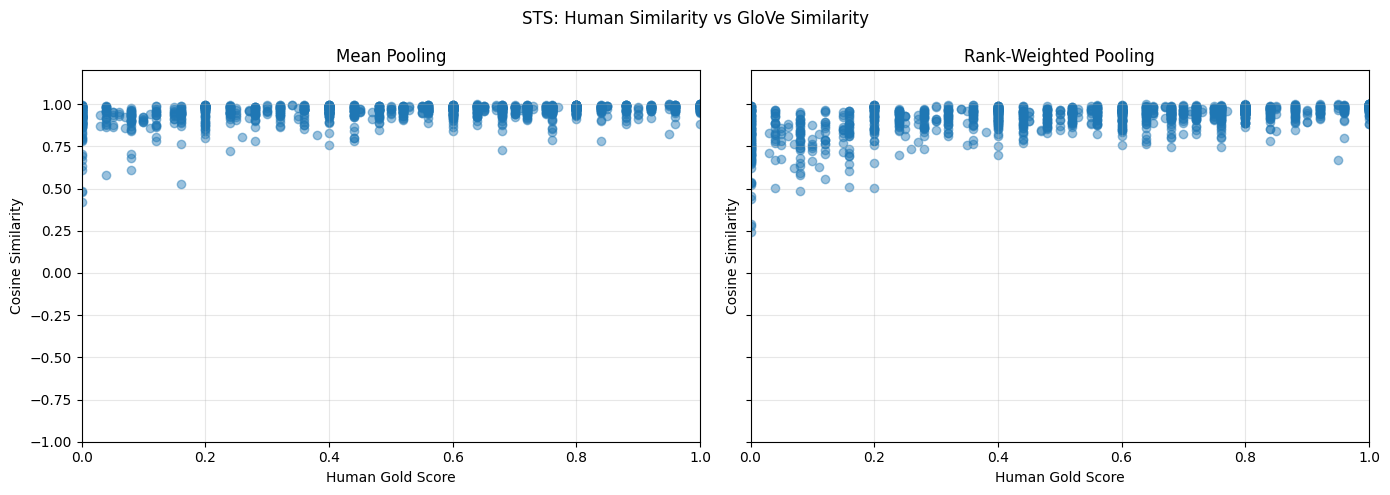

In [ ]:
# Plot the two STS scatter plots on matching axes.
# Draw two scatter plots using the same axis ranges
fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 5),
    sharex=True,
    sharey=True
)

# Plot Mean Pooling results
axes[0].scatter(
    sts_pair_scores["gold_score"],
    sts_pair_scores["cosine_mean"],
    alpha=0.45
)

axes[0].set_title("Mean Pooling")
axes[0].set_xlabel("Human Gold Score")
axes[0].set_ylabel("Cosine Similarity")

# Plot Rank-Weighted Pooling results
axes[1].scatter(
    sts_pair_scores["gold_score"],
    sts_pair_scores["cosine_weighted"],
    alpha=0.45
)

axes[1].set_title("Rank-Weighted Pooling")
axes[1].set_xlabel("Human Gold Score")
axes[1].set_ylabel("Cosine Similarity")

# Use identical axis limits for both plots
for ax in axes:
    ax.set_xlim(0, 1)
    ax.set_ylim(-1, 1.2)

    ax.grid(True, alpha=0.3)

plt.suptitle("STS: Human Similarity vs GloVe Similarity")
plt.tight_layout()
plt.show()

In [ ]:
# Preserve every evaluated record when computing ranks and token counts.
def rank_sts_pairs(scores, embeddings):
    if not scores["gold_score"].between(0, 1).all():
        raise ValueError("Expected STS gold scores on a 0..1 scale")
    ranked = scores.copy()
    ranked["gold_rank"] = normalized_ranks(ranked["gold_score"])
    for method in ("mean", "weighted"):
        ranked[f"{method}_rank"] = normalized_ranks(ranked[f"cosine_{method}"])
        ranked[f"gap_{method}"] = abs(ranked["gold_rank"]-ranked[f"{method}_rank"])
    ranked["weighted_gain"] = ranked["gap_mean"]-ranked["gap_weighted"]
    ranked["oov_count"] = [sum(word not in embeddings for text in (row.sentence1, row.sentence2)
                              for word in tokenize_sentence(text)) for row in ranked.itertuples(index=False)]
    return ranked


In [ ]:
def select_sts_candidates(ranked, mode, k=10):
    if isinstance(k, bool) or not isinstance(k, (int, np.integer)) or k < 1:
        raise ValueError("k must be a positive integer")
    rules = {
        "oov": ((ranked["gold_score"] >= .75) & (ranked["oov_count"] > 0),
                "gap_mean", False, "gold >= 0.75; OOV > 0; largest Mean rank gap"),
        "improved": (ranked["weighted_gain"] > 0, "weighted_gain", False, "positive weighted gain; largest first"),
        "worsened": (ranked["weighted_gain"] < 0, "weighted_gain", True, "negative weighted gain; smallest first"),
    }
    if mode not in rules:
        raise ValueError("Unknown candidate group")
    mask, metric, ascending, rule = rules[mode]
    eligible = ranked.loc[mask]
    top = eligible.sort_values([metric, "sentence1", "sentence2", "gold_score", "cosine_mean", "cosine_weighted"],
                               ascending=[ascending, True, True, True, True, True], kind="mergesort").head(k).copy()
    top["candidate_rank"] = np.arange(1, len(top)+1)
    info = dict(Status="empty" if top.empty else "available", Selection=rule,
                Eligible=len(eligible), Returned=len(top))
    return top.reset_index(drop=True), info


In [ ]:
sts_ranked_pairs = rank_sts_pairs(sts_pair_scores, similarity_embeddings)
sts_candidates, sts_selection_records = {}, []
for mode in ("oov", "improved", "worsened"):
    candidates, info = select_sts_candidates(sts_ranked_pairs, mode, k=10)
    sts_candidates[mode] = candidates
    sts_selection_records.append({"Group": mode, **info})
sts_selection_report = pd.DataFrame(sts_selection_records)
print("Candidate pools: rankings are within each reported group")
display(sts_selection_report)


Candidate pools: rankings are within each reported group


,Group,Status,Selection,Eligible,Returned
0,oov,available,gold >= 0.75; OOV > 0; largest Mean rank gap,120,10
1,improved,available,positive weighted gain; largest first,840,10
2,worsened,available,negative weighted gain; smallest first,531,10


In [ ]:
# Select one available candidate from each analysis group.
selected_sentences = []
for category in ("oov", "improved", "worsened"):
    candidates = sts_candidates[category]
    if candidates.empty:
        print(f"No analysis candidate available for STS group '{category}'; skipped.")
        continue
    selected_sentences.append({**candidates.iloc[0].to_dict(), "category": category})

sts_examples = pd.DataFrame(selected_sentences, columns=[
    "row_id", "sentence1", "sentence2", "gold_score", "cosine_mean", "cosine_weighted",
    "gold_rank", "mean_rank", "gap_mean", "weighted_rank", "gap_weighted",
    "weighted_gain", "oov_count", "candidate_rank", "category",
])


In [ ]:
for example in sts_examples.itertuples(index=False):
    print("Case:", example.category, "| Candidate rank:", example.candidate_rank)
    print("Sentence 1:", example.sentence1)
    print("Sentence 2:", example.sentence2)
    print(f"Human score: {example.gold_score:.2f} | Human rank: {example.gold_rank:.4f}")
    for number, text in enumerate((example.sentence1, example.sentence2), start=1):
        print(f"OOV in sentence {number}:", [word for word in tokenize_sentence(text) if word not in similarity_embeddings])
    print(f"Weighted gain: {example.weighted_gain:+.4f}")
    display(pd.DataFrame([
        {"Method": "Mean", "Cosine": example.cosine_mean, "Model rank": example.mean_rank, "Rank gap": example.gap_mean},
        {"Method": "Rank-Weighted", "Cosine": example.cosine_weighted, "Model rank": example.weighted_rank, "Rank gap": example.gap_weighted},
    ]).round(4))


Case: oov | Candidate rank: 1
Sentence 1: Mt Gox reveals 200,000 'forgotten' bitcoin haul
Sentence 2: Mt Gox finds 200,000 'forgotten' bitcoins
Human score: 1.00 | Human rank: 0.9652
OOV in sentence 1: ['gox', 'bitcoin']
OOV in sentence 2: ['gox', 'bitcoins']
Weighted gain: +0.1676


,Method,Cosine,Model rank,Rank gap
0,Mean,0.8797,0.0631,0.9020
1,Rank-Weighted,0.8850,0.2308,0.7344


Case: improved | Candidate rank: 1
Sentence 1: Two boys playing a game of flag football.
Sentence 2: Two boys are playing flag football.
Human score: 1.00 | Human rank: 0.9652
OOV in sentence 1: []
OOV in sentence 2: []
Weighted gain: +0.4144


,Method,Cosine,Model rank,Rank gap
0,Mean,0.9699,0.4956,0.4695
1,Rank-Weighted,0.9867,0.9100,0.0552


Case: worsened | Candidate rank: 1
Sentence 1: This doesn't answer your question, but:
Sentence 2: This is a part answer to your question
Human score: 0.20 | Human rank: 0.1996
OOV in sentence 1: ["doesn't"]
OOV in sentence 2: []
Weighted gain: -0.3694


,Method,Cosine,Model rank,Rank gap
0,Mean,0.9699,0.4985,0.2990
1,Rank-Weighted,0.9835,0.8679,0.6684


In [ ]:
# Include repetitions when measuring each word's share of the pooling weights.
def sentence_weight_details(text, embeddings, rank_map):
    tokens = tokenize_sentence(text)
    word_counts = {}
    word_ranks = {}
    expected_dim = None

    for word in tokens:
        vector = get_valid_word_vector(word, embeddings, expected_dim)
        if vector is None:
            continue
        if word not in rank_map:
            continue
        rank = rank_map[word]
        if (
            isinstance(rank, (bool, np.bool_))
            or not isinstance(rank, (int, float, np.integer, np.floating))
            or not np.isfinite(rank)
            or rank < 1
        ):
            continue

        if expected_dim is None:
            expected_dim = len(vector)
        # Count every occurrence of the word
        if word not in word_counts:
            word_counts[word] = 0
            word_ranks[word] = rank

        word_counts[word] += 1

    # Prepare the output columns
    columns = [
        "Token",
        "Count",
        "GloVe rank",
        "ln(rank)",
        "Weight share (%)"
    ]

    # Return an empty table if no valid words exist
    if len(word_counts) == 0:

        return pd.DataFrame(columns=columns)

    rows = []

    # Calculate the logarithmic weight for each unique word
    for word, count in word_counts.items():
        rank = word_ranks[word]
        log_weight = np.log(rank)
        # Include repetitions in the total weight
        total_word_weight = count * log_weight
        rows.append({
            "Token": word,
            "Count": count,
            "GloVe rank": rank,
            "ln(rank)": log_weight,
            "_total_word_weight": total_word_weight
        })

    # Calculate the total sentence weight
    total_weight = sum(row["_total_word_weight"] for row in rows)
    # Calculate each word's percentage contribution
    for row in rows:
        if total_weight == 0:
            row["Weight share (%)"] = np.nan
        else:
            row["Weight share (%)"] = (100 * row["_total_word_weight"] / total_weight)
    # Remove the temporary calculation column
    result = pd.DataFrame(rows)

    result = result.drop(
        columns=["_total_word_weight"]
    )

    return result[columns]

# Prefer a worsened example; otherwise inspect an available selected group.
weighting_examples = sts_examples[sts_examples["category"] == "worsened"]
if weighting_examples.empty and not sts_examples.empty:
    print("No worsened example available; showing weights for another selected group.")
    weighting_examples = sts_examples
if weighting_examples.empty:
    print("No STS analysis example available; weight details skipped.")
else:
    weighting_case = weighting_examples.iloc[0]
    print("Weight details for group:", weighting_case.category)
    for text in (weighting_case.sentence1, weighting_case.sentence2):
        print("Sentence:", text)
        display(sentence_weight_details(text, similarity_embeddings, glove_ranks).round(4))


Weight details for group: worsened
Sentence: This doesn't answer your question, but:


,Token,Count,GloVe rank,ln(rank),Weight share (%)
0,this,1,38,3.6376,13.1072
1,answer,1,2169,7.6820,27.6805
2,your,1,393,5.9738,21.5253
3,question,1,996,6.9037,24.8761
4,but,1,35,3.5553,12.8109


Sentence: This is a part answer to your question


,Token,Count,GloVe rank,ln(rank),Weight share (%)
0,this,1,38,3.6376,10.2090
1,is,1,15,2.7081,7.6003
2,a,1,8,2.0794,5.8360
3,part,1,154,5.0370,14.1364
4,answer,1,2169,7.6820,21.5599
5,to,1,5,1.6094,4.5170
6,your,1,393,5.9738,16.7657
7,question,1,996,6.9037,19.3757


<div dir="rtl" style="box-sizing:border-box; max-width:100%; background-color:#FFF8E7; color:#2B2317; border-right:4px solid #D9A441; border-radius:6px; padding:16px 20px; margin:6px 0; line-height:1.9; text-align:right; overflow-wrap:break-word;">

<b style="color:#8A6116;">پاسخ تشریحی ۳.۳ — تحلیل STS</b>

<p><strong>سؤال ۱.</strong> سه نمونه انتخاب‌شده چه تفاوتی در شباهت انسانی و پیش‌بینی دو روش دارند؟ تغییر اختلاف رتبه پس از وزن‌دهی را برای هر نمونه توضیح دهید.</p>

<p><strong>سؤال ۲.</strong> با توجه به واژه‌های OOV و جدول وزن‌ها، علت‌های احتمالی بهبود یا افت روش Rank-Weighted را بررسی کنید. آیا نتیجه بهتر در Spearman به معنای بهبود همه جفت‌جمله‌هاست؟</p>

---

<strong>پاسخ سوال 1</strong>

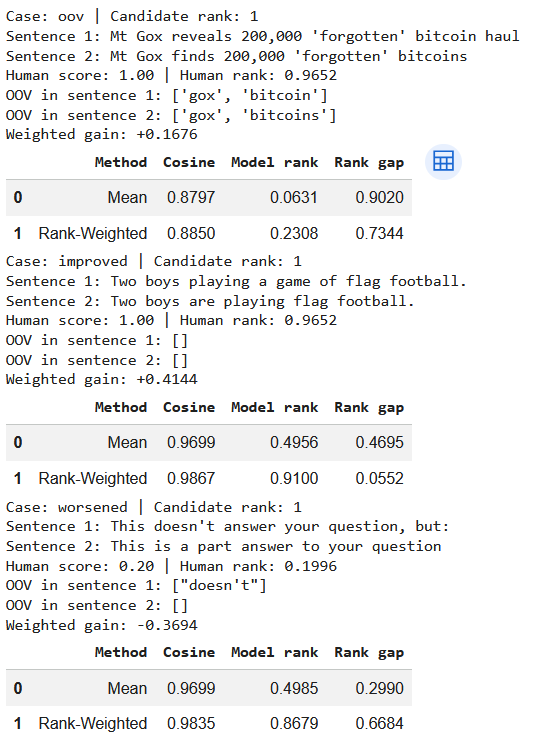

<p>
با توجه به تصویر که خروجی را برای سه نمونه انتخاب شده نشان می دهد داریم:

در نمونه OOV میبینیم امتیاز انسانی 1 است. همچنین هر دو روش، شباهت نسبتا بالایی را تشخیص داده اند؛ اما روش Rank-Weighted شباهت را کمی بیشتر تخمین زده است. در نتیجه اختلاف رتبه آن نیز کمتر شده، و علت احتمالی آن است که به به واژه های مهم تر در جمله (مانند forgotten, reveals/finds, haul) وزن بیشتری داده درحالیکه کلمات OOV رااز محاسبات کنار گذاشته و این باعث شده تمرکزش روی واژه های معنادارتر قرار بگیرد و رتبه بندی اش به قضاوت انسانس نزدیک تر باشد.
</p>

<p>
در نمونه Improved، نمونه ای که خروجی داده ام بهترین حالت بهبود را نشان می دهد. احتلاف رتبه از 0.4695 به 0.0552 رسیده، و Rank-Weighted جمله ها را تقریبا در رتبه ای معادل با رتبه انسانی قرار داده است.علت آن است که دو جمله تقریبا از نظر معنایی برابر هستند . در روش Mean،تمام واژه ها سهم یکسانی دارند و کلمات با اهمیت معنایی کمتر، در بردار نهایی جمله کمی نویز ایجاد می کنند. اما در روش Rank-Weighted کلمات مهم تر، وزن بیشتری گرفته و تاثیر بیشتری در رتبه نهایی می گذارند و این باعث می شود رتبه مدل له رتبه انسانی نزدیک بشود.
</p>

<p>
در نمونه Worsened هم مشاهده می کنیم که وزن دهی، عملکرد مدل ر بدتر کرده است.چراکه اختلاف رتبه از 0.2990 به 0.6684 زیاد شده.همچنین درحالیکه ارزیاب انسانی دو جمله را نسبتا کم شباهت ارزیابی کرده است، روش Rank-Weighted آنها را مشابه تر از قبل تشخیص داده. علت اصلی هم در بخش  doesn't answer قرار دارد. وجودش باعث تغییر معنای جمله شه اما پس از وزن دهی، تمرکز مدل بیشتر روی واژه های مشترک قرار گرفته و باعث شده مدل تاثیر نفی را به خوبی اعمال نکند و دو جمله را بیش از حد مشابه توصیف کند.
</p>

---

<strong>پاسخ سوال 2</strong>

<p>
با توجه به واژه‌های OOV و جدول وزن‌ها، عملکرد روش Rank-Weighted به نحوه توزیع وزن میان کلمات و همچنین وجود یا عدم وجود بردار برای واژه‌ها بستگی دارد. در این روش، کلمات بر اساس رتبه فراوانی آن‌ها در GloVe وزن‌دهی می‌شوند؛ بنابراین برخی واژه‌ها سهم بیشتری در تشکیل بردار جمله پیدا می‌کنند. این ویژگی می‌تواند در مواردی باعث بهبود نتایج شود، زیرا کلمات معنایی مهم‌تر تأثیر بیشتری بر نمایش جمله خواهند داشت. برای مثال، در نمونه «flag football» وزن‌دهی باعث شد شباهت بالای دو جمله بهتر منعکس شود و اختلاف رتبه مدل با رتبه انسانی به شکل محسوسی کاهش یابد.
</p>

<p>
از طرف دیگر، وجود واژه‌های OOV  می‌تواند بر نتیجه اثر بگذارد. در نمونه مربوط به Mt Gox، واژه‌های «gox»، «bitcoin» و «bitcoins» خارج از واژگان بودند و در محاسبه بردار دخالت نداشتند. در چنین شرایطی، مدل تنها بر اساس کلمات باقی‌مانده تصمیم‌گیری می‌کند. اگر واژه‌های حذف‌شده نقش اصلی در معنا نداشته باشند، وزن‌دهی می‌تواند حتی موجب بهبود عملکرد شود؛ اما اگر بخش مهمی از اطلاعات معنایی در واژه‌های OOV قرار داشته باشد، کیفیت تخمین شباهت کاهش خواهد یافت.
</p>

<p>
جدول وزن‌های نمونه Worsened نیز نشان می‌دهد که وزن زیادی به کلمات مشترکی مانند answer، question و your اختصاص یافته است، در حالی که تفاوت معنایی اصلی دو جمله در وجود واژه doesn't نهفته است. در نتیجه، روش Rank-Weighted بیش از حد بر اشتراک واژگانی تمرکز کرده و اثر نفی را به اندازه کافی منعکس نکرده است. این موضوع باعث شده دو جمله از دید مدل بسیار مشابه‌تر از ارزیابی انسانی به نظر برسند و اختلاف رتبه افزایش یابد.
</p>

<p>
در نهایت، باید توجه داشت که بهبود مقدار Spearman به معنای بهبود همه جفت‌جمله‌ها نیست. ضریب Spearman تنها میزان همخوانی کلی رتبه‌بندی مدل با رتبه‌بندی انسانی را در سطح کل مجموعه داده اندازه‌گیری می‌کند. بنابراین ممکن است برخی جفت‌جمله‌ها عملکرد بهتری پیدا کنند و برخی دیگر بدتر شوند، اما اگر مجموع تغییرات باعث نزدیک‌تر شدن رتبه‌بندی کلی مدل به رتبه‌بندی انسان شود، مقدار Spearman افزایش خواهد یافت. نمونه‌های انتخاب‌شده دقیقاً این موضوع را نشان می‌دهند؛ به طوری که برخی موارد پس از وزن‌دهی بهبود چشمگیری داشته‌اند، برخی اندکی بهتر شده‌اند و برخی نیز عملکرد ضعیف‌تری پیدا کرده‌اند، اما نتیجه نهایی بر اساس اثر تجمعی همه نمونه‌ها تعیین می‌شود.
</p>

</div>


<div dir="rtl" align="right">

### ۳.۴ بررسی اثر ترتیب واژه‌ها

**صورت مسئله**

دو جمله زیر از واژه‌های یکسانی تشکیل شده‌اند، اما ترتیب آن‌ها متفاوت است:

1. `The dog chased the man.`
2. `The man chased the dog.`

**آنچه باید انجام دهید**

- با استفاده از دو روش بخش قبل، بردار هر جمله را محاسبه کنید.
- در هر روش، بردار دو جمله را با `np.allclose` مقایسه کنید و مقدار Cosine و بیشترین اختلاف مطلق مؤلفه‌ها را گزارش دهید.

**خروجی مورد انتظار**

- جدول تعداد تکرار واژه‌ها و جدول مقایسه نتایج دو روش با ستون‌های `Method`، `Same vector (allclose)`، `Max absolute difference` و `Cosine`.

**نکات و محدودیت‌ها**

- برای `np.allclose` از `rtol=1e-10` و `atol=1e-12` استفاده کنید. این آزمایش مستقل از ارزیابی STS است و نباید به داده‌های Test اضافه شود.

</div>


In [ ]:
# ==============================================================
# Part 3.4 - Controlled word-order experiment
# ==============================================================

# Provided inputs: change word order while preserving token multiplicities.
order_sentences = ("The dog chased the man.", "The man chased the dog.")
order_tokens = [tokenize_sentence(text) for text in order_sentences]
assert order_tokens[0] != order_tokens[1]
assert sorted(order_tokens[0]) == sorted(order_tokens[1])
assert all(word in similarity_embeddings and is_valid_embedding(similarity_embeddings[word])
           for tokens in order_tokens for word in tokens)
for number, text in enumerate(order_sentences, start=1):
    print(f"Sentence {number}:", text)
order_token_counts = pd.DataFrame([
    {"Token": word, "Sentence 1 count": order_tokens[0].count(word),
     "Sentence 2 count": order_tokens[1].count(word)}
    for word in sorted(set(order_tokens[0]))
])
display(order_token_counts)


Sentence 1: The dog chased the man.
Sentence 2: The man chased the dog.


,Token,Sentence 1 count,Sentence 2 count
0,chased,1,1
1,dog,1,1
2,man,1,1
3,the,2,2


In [ ]:
# Compare the two controlled sentences within each pooling method.
comparison_results = []

# Calculate sentence embeddings for both sentences
mean_vector_1 = mean_sentence_embedding(order_sentences[0], similarity_embeddings)
mean_vector_2 = mean_sentence_embedding(order_sentences[1], similarity_embeddings)

weighted_vector_1 = weighted_sentence_embedding(order_sentences[0], similarity_embeddings, glove_ranks)
weighted_vector_2 = weighted_sentence_embedding(order_sentences[1], similarity_embeddings, glove_ranks)

# Store the results for both pooling methods
methods = [("Mean", mean_vector_1, mean_vector_2), ("Rank-Weighted", weighted_vector_1, weighted_vector_2)]
for method_name, vector_1, vector_2 in methods:
    # Check whether both sentence vectors are valid
    if vector_1 is None or vector_2 is None:
        raise ValueError(f"Invalid sentence vector in {method_name}")

    same_vector = np.allclose(vector_1, vector_2, rtol=1e-10, atol=1e-12)
    # Calculate the maximum absolute difference
    max_difference = np.max(np.abs(vector_1 - vector_2))
    # Calculate cosine similarity
    cosine = manual_cosine_similarity(vector_1, vector_2)
    # Save the results
    comparison_results.append({"Method": method_name, "Same vector (allclose)": same_vector, "Max absolute difference": max_difference, "Cosine": cosine})

# Display the final comparison table
order_comparison = pd.DataFrame(comparison_results)
display(order_comparison.round(10))

,Method,Same vector (allclose),Max absolute difference,Cosine
0,Mean,True,0.0,1.0
1,Rank-Weighted,True,0.0,1.0


<div dir="rtl" style="box-sizing:border-box; max-width:100%; background-color:#FFF8E7; color:#2B2317; border-right:4px solid #D9A441; border-radius:6px; padding:16px 20px; margin:6px 0; line-height:1.9; text-align:right; overflow-wrap:break-word;">

<b style="color:#8A6116;">پاسخ تشریحی ۳.۴ — ترتیب واژه‌ها</b>

<p><strong>سؤال ۱.</strong> نتیجه مقایسه بردار دو جمله در هر روش چیست؟ آیا روش Rank-Weighted می‌تواند تفاوت ترتیب واژه‌ها را نشان دهد؟</p>

<p><strong>سؤال ۲.</strong> این آزمایش چه محدودیتی از روش‌های تجمیع به‌کاررفته در این سؤال را نشان می‌دهد؟</p>

---

<strong>پاسخ سوال 1</strong>

<p>
با توجه به نتایج خروجی سلول قبل، مشاهده می شود که در هر دو روش، بردارهای جملات یکسان هستند؛ همانطور که در جدول مشاهده می شود، مقدار same vector برابر true و مقدار cosine similarity برابر 1 است.
</p>

<p>
حتی بدون انجام این آزمون هم با توجه به روابط هر دو روش مشخص است که هیچکدام از این روش ها ترتیب جملات را اعمال نمی کنند.
</p>

---

<strong>پاسخ سوال 1</strong>

<p>
این آزمایش (بهمراه بررسی رابطه هر دو روش) نشان می دهد که هیچکدام از روش های Mean Pooling  و Rank-Weighted Pooling نسبت به ترتیب واژه ها حساس نیستند و اطلاعات مربوط به ساختار نحوی جمله را حفظ نمی کنند؛ در مثال بالا هم دیدیم که با اینکه واژگان دو جمله دقیقا یکسان بود، اما معنای دو جمله کاملا با هم متفاوت بود اما این دو روش هیچ تفاوتی بین معنای این دو جمله قائل نبودند.
پس نشان می دهد روش های ساده تجمیع بردار واژها برای درک کامل معنای جمله کافی نیستند. پس برای برطرف کردن این محدودیت باید روش های پیچیده تری را استفاده کرد.
</p>

</div>


---

<div dir="rtl" align="right">

## جمع‌بندی

در چند بند، یافته‌های خود را از کل تکلیف جمع‌بندی کنید.

- **مهم‌ترین نتایج به‌دست‌آمده:**

<p>
در بخش اول، الگوریتم SGNS را از پایه پیاده‌سازی و با استفاده از مجموعه داده Brown آموزش دادم. پس از حذف واژه‌هایی که فراوانی کمتر از ۵ داشتند، تعداد واژگان به ۴۳۹۷ واژه رسید و در مجموع ۵۳۰۲۶۶ جفت Target-Context ساخته شد. همچنین صحت محاسبات گرادیان با استفاده از روش Finite Difference بررسی شد که خطای نسبی آن برای ماتریس‌های W و C به‌ترتیب حدود $$(2.28\times10^{-10})$$ و $$(6.41\times10^{-10})$$ بود و در نتیجه Gradient Check با موفقیت انجام شد. در طول ۶۵ Epoch آموزش، مقدار Fixed-Subset Loss از ۲.۹۵۷۱ به حدود ۱.۹۸۶۸ کاهش پیدا کرد که نشان‌دهنده یادگیری مدل بود. در مقایسه با GloVe نیز مشاهده شد که مدل از پیش آموزش‌دیده GloVe در آزمایش‌های Nearest Neighbors و Analogy عملکرد بهتری دارد. برای مثال، در رابطه man : he :: woman : she، واژه she توسط GloVe در رتبه اول و توسط SGNS در رتبه چهارم قرار گرفت. همچنین مجموع واریانس توضیح‌داده‌شده توسط دو مؤلفه اول PCA برای GloVe برابر ۶۲.۱۲ درصد و برای SGNS برابر ۴۳.۲۸ درصد بود.
</p>

<p>
در بخش دوم، یک مدل Logistic Regression با استفاده از شش ویژگی استخراج‌شده از متن نظرات کاربران IMDB و با پیاده‌سازی دستی SGD آموزش داده شد. وزن مثبت ویژگی positive_count و وزن منفی ویژگی negative_count با انتظارات اولیه سازگار بودند و به‌ترتیب برابر با ۱.۵۹۶۹۷۴ و ۱.۵۴۴۰۵۲- به دست آمدند. در آستانه تصمیم‌گیری ۰.۵، مدل به Accuracy برابر با ۷۳.۲۵ درصد و F1-Score برابر با ۷۳.۴۵ درصد رسید. با افزایش Threshold به ۰.۸، مقدار Precision از حدود ۷۲.۹ درصد به ۸۷.۷ درصد افزایش یافت، اما Recall از ۷۴ درصد به ۲۵ درصد کاهش پیدا کرد. این موضوع نشان داد که افزایش آستانه باعث سخت‌گیرانه‌تر شدن مدل در تشخیص نظرات مثبت می‌شود. همچنین در بررسی Learning Rate مشاهده شد که مقدار ۰.۰۱ روند آموزشی نسبتاً پایداری با Loss نهایی حدود ۰.۵۳۷۹ ایجاد می‌کند، در حالی که مقدار بزرگ‌تر ۱۵ باعث نوسانات شدید Loss و عملکرد نامناسب در فرایند یادگیری شد.
</p>

<p>
در بخش سوم، با استفاده از بردارهای ۵۰بعدی GloVe، شباهت واژه‌ها و جمله‌ها بررسی شد. در ارزیابی Word Similarity، ضریب Spearman برای مجموعه WordSim-353 برابر با ۰.۵۲۴۷ و برای SimLex-999 برابر با ۰.۲۶۵۲ به دست آمد. پوشش واژگانی مدل نیز مناسب بود و به‌ترتیب ۹۸.۵۸ و ۹۹.۶۰ درصد از جفت‌های این دو مجموعه قابل ارزیابی بودند. در ارزیابی شباهت جمله‌ها روی مجموعه STS Benchmark نیز روش Mean Pooling به ضریب Spearman برابر با ۰.۴۲۷۶ رسید، در حالی که این مقدار برای روش Rank-Weighted Pooling برابر با ۰.۵۳۱۰ بود. بنابراین وزن‌دهی بر اساس رتبه واژه‌ها در این آزمایش توانست همخوانی کلی پیش‌بینی مدل با قضاوت انسانی را بهبود دهد. البته بررسی نمونه‌های انتخاب‌شده نشان داد که این بهبود در تمام جفت‌جمله‌ها اتفاق نمی‌افتد و گاهی حتی باعث افزایش اختلاف با ارزیابی انسانی می‌شود. در نهایت، در آزمایش اثر ترتیب واژه‌ها مشاهده شد که برای هر دو روش Mean و Rank-Weighted، بردار دو جمله‌ با واژگان یکسان و ترتیب متفاوت کاملا یکسان است و Cosine Similarity آن‌ها برابر با ۱ به دست می‌آید.
</p>

---

- **چالش‌ها و محدودیت‌های روش‌های به‌کاررفته:**

<p>
یکی از مهم‌ترین محدودیت‌های مشاهده‌شده در بخش اول، تفاوت حجم داده‌های آموزشی و اندازه واژگان مدل SGNS با GloVe بود. مدل SGNS تنها روی زیرمجموعه‌ای از Brown با ۴۳۹۷ واژه آموزش داده شد، در حالی که GloVe از پیش روی مجموعه داده بسیار بزرگ‌تری آموزش دیده و در آزمایش Analogy دارای ۴۰۰ هزار واژه بود. بنابراین مقایسه عملکرد این دو مدل، در شرایط متفاوتی است. همچنین کیفیت نمایش‌های برداری به فراوانی واژه‌ها در داده آموزشی و تنظیماتی مانند Window Size و تعداد Negative Samples وابسته است. در بخش دوم نیز استفاده از تعداد محدودی ویژگی مبتنی بر شمارش واژه‌ها باعث می‌شود مدل نتواند تمام جنبه‌های معنایی متن را تشخیص دهد. برای مثال، وجود یک واژه مثبت در جمله‌ای با ساختار منفی لزوما به معنای مثبت بودن احساس نویسنده نیست و ویژگی‌هایی مانند شمارش واژه‌ها به‌تنهایی نمی‌توانند چنین روابطی را به‌خوبی تشخیص دهند.
</p>

<p>
در بخش سوم نیز مشخص شد که استفاده از Word Embeddings ثابت و روش‌های ساده تجمیع بردارها محدودیت‌های خاص خود را دارد. از آنجا که این بردارها مستقل از بافت هر جمله هستند، نمی‌توانند تمام تغییرات معنایی واژه‌ها در موقعیت‌های مختلف را در نظر بگیرند. علاوه بر این، واژه‌های خارج از واژگان (OOV) از محاسبات حذف می‌شوند و در نتیجه ممکن است بخشی از اطلاعات معنایی جمله از دست برود. روش Rank-Weighted نیز با وجود بهبود نتیجه کلی در STS، در بعضی نمونه‌ها بیش از حد به واژه‌های مشترک توجه می‌کند و نمی‌تواند نقش کلماتی مانند doesn't را که ممکن است معنای جمله را  تغییر دهند، به‌درستی منعکس کند. مهم‌تر از همه، آزمایش ترتیب واژه‌ها نشان داد که هیچ‌یک از دو روش Mean Pooling و Rank-Weighted Pooling اطلاعات مربوط به ترتیب و ساختار نحوی جمله را حفظ نمی‌کنند؛ بنابراین حتی دو جمله با معنای متفاوت ممکن است  یک بردار یکسان داشته باشند.
</p>

---


- **پیشنهاد برای بهبود یا ادامه‌ی کار:**

<p>
رای بهبود نتایج این تمرین، در بخش SGNS می‌توان از یک مجموعه داده آموزشی بزرگ‌تر استفاده کرد و تأثیر تغییر پارامترهایی مانند اندازه پنجره، تعداد نمونه‌های منفی و ابعاد Embedding را به‌صورت آزمایشی بررسی کرد. همچنین بهتر است ارزیابی کیفیت بردارها با استفاده از مجموعه بزرگ‌تری از آزمون‌های Analogy و Nearest Neighbors انجام شود تا نتیجه‌گیری به چند نمونه محدود وابسته نباشد. در بخش طبقه‌بندی احساس نیز می‌توان با اضافه کردن ویژگی‌هایی برای تشخیص Negation، ترکیب‌های چندکلمه‌ای و ارتباط میان واژه‌ها، توانایی مدل را در درک بهتر مفهوم جملات افزایش داد. در نهایت، برای ارزیابی شباهت جمله‌ها پیشنهاد می کنم بجای تکیه صرف بر روش‌های ساده تجمیع بردارهای ثابت، از روش‌هایی استفاده شود که ترتیب واژه‌ها و بافت معنایی آن‌ها را در نظر می‌گیرند.
</p>

</div>

<div dir="rtl" align="right">

## منابع و ابزارهای کمکی

هر منبعی که در انجام این تکلیف از آن استفاده کرده‌اید (مقاله، مستندات کتابخانه، مخزن کد، پست وبلاگ) و نیز — مطابق سیاست درس — هرگونه استفاده از ابزارهای هوش مصنوعی مولد را در جدول زیر ذکر کنید. اعلام نکردن منابع و ابزارهای استفاده‌شده، مصداق نقض صداقت علمی است.

| ردیف | منبع یا ابزار | محل استفاده (شماره‌ی بخش) | نحوه‌ی استفاده |
|---|---|---|---|
| ۱ | Gemini(link="https://share.gemini.google/G8806jiLlyVH") | Part1 | درک کامل صورت سوال و درخواست راهنمایی برای تقسیم بندی کار |
| ۲ | ChatGPT(link="https://chatgpt.com/share6aff19c6-a364-83eb-9e4c-81deb97d5c8a") | Part2/Part3 | درک کامل صورت سوال + ارزیابی و صحت سنجی خروجی ها + پیشنهاد برای تکمیل برخی از سلول های کد |



</div>

<div dir="rtl" align="right">

## چک‌لیست پیش از ارسال

- [ ] جدول مشخصات دانشجو تکمیل شده است.
- [ ] همه‌ی سلول‌های دارای نشانه‌ی `WRITE YOUR CODE HERE` تکمیل شده‌اند.
- [ ] همه‌ی سلول‌های پاسخ تشریحی تکمیل شده و هیچ `{{پاسخ_خود_را_اینجا_بنویسید}}` باقی نمانده است.
- [ ] بخش جمع‌بندی و جدول منابع و ابزارهای کمکی تکمیل شده است.
- [ ] نوت‌بوک با `Restart & Run All` بدون خطا اجرا شده و خروجی همه‌ی سلول‌ها در فایل ذخیره شده است.
- [ ] نام فایل مطابق الگوی `NLP_CA{n}_{LASTNAME}_{STUDENTID}.ipynb` است.

</div>

---

<div dir="rtl" align="right">

## قوانین تحویل و صداقت علمی

### ۱. مهلت و نحوه‌ی ارسال

- مهلت تحویل: {{تاریخ_تحویل}}
- مهلت تحویل با تأخیر: {{تاریخ_تحویل_با_تأخیر}} — با اعمال {{جریمه_تأخیر}}
- فایل ارسالی باید با این قالب نام‌گذاری شود: `NLP_CA{n}_{LASTNAME}_{STUDENTID}.ipynb`
- تنها فایل نوت‌بوک اجراشده پذیرفته می‌شود. به تکالیفی که به‌صورت کاغذی تحویل داده شوند یا به‌صورت تصویر در سامانه بارگذاری شوند، ترتیب اثری داده نخواهد شد.

### ۲. صداقت علمی

- نوت‌بوک تعداد مشخصی از دانشجویان که به‌صورت تصادفی انتخاب می‌شوند بررسی خواهد شد. این بررسی‌ها اطمینان حاصل می‌کنند که کدی که نوشته‌اید واقعاً پاسخ‌های موجود در نوت‌بوک شما را تولید می‌کند. ارائه‌ی پاسخ‌های درست بدون کدی که آن پاسخ‌ها را تولید کرده باشد، موردی جدی از عدم صداقت علمی محسوب می‌شود.
- بررسی‌های خودکار برای تشخیص سرقت علمی روی نوت‌بوک‌ها انجام می‌شود. کپی کردن کد از دیگران نیز موردی جدی از عدم صداقت علمی است.
- این تکلیف باید به‌صورت تک‌نفره انجام شود و پاسخ‌ها باید نتیجه‌ی فعالیت شخص نویسنده باشد؛ هم‌فکری و نوشتن مشترک تمرین نیز مجاز نیست. در صورت مشاهده‌ی تشابه، نمره‌ی تمرین برای همه‌ی افراد مشارکت‌کننده صفر و موضوع به استاد گزارش می‌شود.

### ۳. کد و گزارش

- همه‌ی کدهای پیوست گزارش باید قابلیت اجرای مجدد داشته باشند. اگر اجرای دوباره به تنظیمات خاصی نیاز دارد، آن تنظیمات را در گزارش ذکر کنید.
- همه‌ی کدها باید توسط خودتان اجرا شده و نتایج اجرا در فایل ارسالی قابل مشاهده باشد. به کدهایی که نتیجه‌ی اجرای آن‌ها در فایل ارسالی مشخص نباشد نمره‌ای تعلق نمی‌گیرد.
- خوانایی گزارش و دقت تحلیل‌ها در نمره‌دهی اهمیت ویژه دارد.

### ۴. پرسش و پاسخ

- پرسش‌های خود درباره‌ی این تکلیف را در {{کانال_پرسش_و_پاسخ}} یا از طریق ایمیل {{ایمیل_دستیار}} مطرح کنید و در ایمیل‌ها حتماً چیف تی‌ای درس (msabour.official@gmail.com) را cc کنید.
